# 12 — End-to-End Deep Learning Project in Bioinformatics

### From a clinical question to a documented, honestly evaluated model: classifying breast-mass cytology

**Learning path:** `Deep Learning / Keras`  
**Notebook:** 12 of 12 — the capstone project  
**Level:** Advanced  
**Primary tools:** Python, NumPy, pandas, Matplotlib, Keras 3  
**Dataset:** UCI *Breast Cancer Wisconsin (Diagnostic)* — 569 fine-needle-aspirate (FNA) samples, 30 nuclear features, benign or malignant

---

This notebook is different from the others. There is no new technique to learn; the goal is to **run one complete research project** with everything from Notebooks 01–11, from the question to the final report:

| Phase | Sections |
|---|---|
| **A. Review and design** | 1 (review of the whole series), 2 (the research question and the decision problem) |
| **B. Data** | 3–7 (loading, validity checks, exploration, preprocessing decisions, splitting) |
| **C. Methods** | 8–9 (the mathematics and the tools: logistic regression, scoring rules, calibration, decision theory) |
| **D. Modelling** | 10–13 (baselines, neural-network design, hyperparameter search, honest comparison) |
| **E. Evaluation** | 14–17 (final test, calibration and threshold, clinical usefulness, uncertainty) |
| **F. Interpretation and delivery** | 18–22 (what the model uses, errors, learning curves, limitations, saving, reporting) |

## Learning objectives

By the end, you should be able to:

1. Turn a biomedical question into a well-posed prediction problem, including **the cost of different errors**, and write down the evaluation protocol **before** looking at results.
2. Perform validity checks, exploratory analysis, and preprocessing **without leakage**.
3. Implement **logistic regression from scratch** (Newton's method), verify its gradient, and use it as an honest baseline for a neural network.
4. Design, tune (**random search with cross-validation**), and train a regularized MLP, and combine several into an **ensemble**.
5. Compare models with **repeated cross-validation** and **paired tests**, and evaluate once on a held-out test set with confidence intervals.
6. Assess **calibration** (reliability diagrams, Platt scaling) and choose a **decision threshold** from misclassification costs, then evaluate **clinical usefulness** with **decision curves** (net benefit).
7. Explain what the model uses (**permutation importance**, grouped), quantify **uncertainty** (ensemble disagreement), and read **learning curves**.
8. Write the limitations and a **reproducible report**: saved model, preprocessing, threshold, metadata, and a model card.

## 1. Review: the toolkit from Notebooks 01–11

Every step of this project reuses an idea you have already met. Use this table as a checklist while reading.

| Notebook | Core idea | Where it returns in this project |
|---|---|---|
| 01–02 | neurons, layers, activation functions, gradients, backpropagation | the MLP (Section 11) and the logistic-regression gradient (Section 8) |
| 03 | Keras workflow: Sequential API, compile, fit, callbacks, normalization **inside** the model, no leakage | model construction, early stopping, preprocessing fitted on training data only |
| 04 | softmax, cross-entropy as negative log-likelihood, gradient $p-y$, imbalance, macro metrics, bootstrap intervals | sigmoid + binary cross-entropy, log loss as the main metric, class imbalance (37% malignant) |
| 05 | regression, losses, conditioning and feature scaling, bias–variance, prediction intervals | standardization, collinear features, ridge penalty, learning curves |
| 06 | optimizers, learning rate, L2, L1, Dropout, BatchNorm, early stopping, multi-seed experiments | the hyperparameter search space, regularization of a small-data MLP |
| 07 | evaluation: confidence intervals, leakage, ROC/AUC, PR, calibration, thresholds and costs, CV, nested CV, winner's curse, paired tests | the whole evaluation protocol (Phases D–E) |
| 08–09 | CNNs, transfer learning, augmentation | not needed for tabular features — an example of *choosing the right tool* |
| 10 | position-aware design, motifs, grouped splits, ensembles, mutagenesis | ensembling, interpretation by perturbation |
| 11 | representation learning, PCA, reconstruction | PCA for exploration (Section 5) |

### 1.1 The ten rules we will follow

1. **Write the question, the metric, and the protocol before modelling.**
2. **Split first.** The test set is touched once, at the end.
3. Everything that learns from data (scaling, transformations, hyperparameters, thresholds, calibration) is fitted **inside** the training data of each fold.
4. **Start with simple baselines** (majority class, logistic regression, nearest neighbours) and make the neural network beat them *honestly*.
5. Report **uncertainty** (intervals, folds, seeds), never a single number.
6. Compare models with **paired** procedures on identical data.
7. Judge **probabilities** (calibration, proper scoring rules), not only labels.
8. Choose the **threshold from the costs** of errors, on development data.
9. Ask whether the model is **useful** (decision curve), not only accurate.
10. State the **limitations** and make the work **reproducible**.

## 2. The research question and the decision problem

### 2.1 Biological and clinical background

A **fine-needle aspirate (FNA)** takes a small sample of cells from a breast mass with a thin needle; the cells are smeared on a slide, stained, and examined under a microscope. A pathologist judges whether the cells look malignant from the **appearance of the cell nuclei**: their size, shape regularity, and texture. In the dataset of Street, Wolberg, and Mangasarian (1993), a digitized image of the slide is analysed by software that **outlines the nuclei** and computes ten measurements for each nucleus. For each image, the **mean**, the **standard error**, and the **"worst"** (mean of the three largest values) of every measurement are reported, giving $10 \times 3 = 30$ features.

| Measurement (computed per nucleus) | Meaning |
|---|---|
| radius | mean distance from the centre to points on the perimeter |
| texture | standard deviation of the grey-scale values |
| perimeter, area | size of the nucleus |
| smoothness | local variation in radius lengths |
| compactness | $\text{perimeter}^2/\text{area} - 1$ |
| concavity | severity of concave portions of the contour |
| concave points | number of concave portions of the contour |
| symmetry | symmetry of the nucleus |
| fractal dimension | "coastline approximation" $- 1$ (roughness of the contour) |

### 2.2 The research question

> *Can a neural network, trained on nuclear features from FNA images, discriminate malignant from benign breast masses — with **calibrated probabilities** and a **decision rule that respects the unequal costs of errors** — and does it add anything over a simple logistic regression?*

Note that the second half of the question is as important as the first: for a dataset of this kind, *every reasonable model* reaches a high accuracy, and the scientific value lies in careful evaluation, calibration, and honesty about what the model adds.

### 2.3 Formal problem and the decision rule (declared in advance)

Let $x \in \mathbb{R}^{30}$ be the features and $y \in \{0, 1\}$ the diagnosis ($1$ = malignant, the **positive** class). The model outputs $\hat{p}(x) \approx \mathbb{P}(y = 1 \mid x)$. The two errors are not equally serious:

| Error | Consequence | Cost (declared) |
|---|---|---|
| **False negative** (malignant called benign) | delayed diagnosis and treatment | $c_{FN} = 5$ |
| **False positive** (benign called malignant) | further tests, anxiety | $c_{FP} = 1$ |

The ratio 5 : 1 is an **assumption for this exercise** (real costs must come from clinicians and patients). From the derivation of Notebook 07, the decision that minimizes the expected cost for a calibrated probability is

$$
\text{call malignant if}\quad \hat{p}(x) \;\ge\; p^{*} = \frac{c_{FP}}{c_{FP} + c_{FN}} = \frac{1}{6} \approx 0.167 .
$$

### 2.4 The evaluation protocol (fixed before we look at the data)

| Item | Decision |
|---|---|
| Data split | 20% **test** set (stratified), never used until Section 14; the remaining 80% is the **development set** |
| Model development | 5-fold stratified cross-validation (repeated 3 times) on the development set; hyperparameters by random search inside cross-validation |
| Primary metric (selection) | **log loss** (cross-entropy), a proper scoring rule that rewards honest probabilities |
| Secondary metrics | AUC, Brier score, calibration error, sensitivity and specificity at $p^{*}$, expected cost, net benefit |
| Candidates | majority class, logistic regression (from scratch), $k$-nearest neighbours, MLP, MLP ensemble |
| Decision threshold | $p^{*} = 1/6$ applied to **calibrated** probabilities (Platt scaling fitted on out-of-fold development predictions) |
| Final report | the test set, once, with 95% intervals; paired tests against the logistic-regression baseline |

## 3. Set up the environment

We use Keras 3 with the TensorFlow backend. Preprocessing, the baselines, the metrics, and the statistics are written in **NumPy** (as in Notebooks 07 and 11), so every formula can be checked; Keras is used for the neural networks.

**Runtime.** The hyperparameter search and the repeated cross-validation train a few hundred small networks on 455 samples: roughly 10–20 minutes on a CPU. Set `QUICK_MODE = True` for a much shorter first run (fewer configurations, repeats, and ensemble members).

In [ ]:
# If needed, install the packages in the active Jupyter environment:
# %pip install -U keras tensorflow numpy pandas matplotlib
# (optional, only for the alternative download in Section 4: %pip install ucimlrepo)

In [1]:
# Select the backend BEFORE importing Keras.
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

import sys, json, math, time, urllib.request
from math import comb, lgamma

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import keras

SEED = 42
keras.utils.set_random_seed(SEED)

QUICK_MODE = False                         # True: a much shorter run for a first read
N_REPEATS = 1 if QUICK_MODE else 3         # repeats of the 5-fold cross-validation
N_CONFIGS = 4 if QUICK_MODE else 12        # random-search configurations
ENSEMBLE_SIZE = 3 if QUICK_MODE else 10    # networks per ensemble
N_BOOT = 500 if QUICK_MODE else 2000       # bootstrap resamples
N_PERM = 5 if QUICK_MODE else 20           # repetitions of each permutation (importance)

COST_FN, COST_FP = 5.0, 1.0                # declared in Section 2.3
P_STAR = COST_FP / (COST_FP + COST_FN)     # cost-optimal threshold for calibrated probabilities

ARTIFACT_DIR = "artifacts_12"
FIG_DIR = "figures_12"
for folder in (ARTIFACT_DIR, FIG_DIR):
    os.makedirs(folder, exist_ok=True)

print("Python :", sys.version.split()[0])
print("Keras  :", keras.__version__, "| backend:", keras.backend.backend())
print("NumPy  :", np.__version__, "| pandas:", pd.__version__)
print(f"Quick mode: {QUICK_MODE} | repeats {N_REPEATS} | configurations {N_CONFIGS} | ensemble size {ENSEMBLE_SIZE} | p* = {P_STAR:.4f}")

Python : 3.11.0
Keras  : 3.15.1 | backend: tensorflow
NumPy  : 2.4.6 | pandas: 2.3.3
Quick mode: False | repeats 3 | configurations 12 | ensemble size 10 | p* = 0.1667


In [2]:
COLORS = {"blue": "#2563EB", "orange": "#F59E0B", "green": "#10B981", "red": "#EF4444",
          "purple": "#8B5CF6", "gray": "#6B7280", "dark": "#111827", "light": "#E5E7EB",
          "teal": "#0D9488", "pink": "#DB2777"}
CLASS_COLORS = {"benign": COLORS["teal"], "malignant": COLORS["red"]}
MODEL_COLORS = {"Majority class": COLORS["gray"], "Logistic regression": COLORS["purple"], "k-nearest neighbours": COLORS["teal"],
                "MLP (single)": COLORS["blue"], "MLP ensemble": COLORS["orange"]}
GROUP_COLORS = {"mean": COLORS["blue"], "se": COLORS["green"], "worst": COLORS["orange"]}

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": COLORS["gray"], "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": COLORS["light"], "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelsize": 10,
    "axes.labelcolor": COLORS["dark"], "xtick.color": COLORS["dark"], "ytick.color": COLORS["dark"],
    "font.size": 10, "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 2.0,
})

SAVE_FIGURES = True
def finish(fig, name, pad=1.0, tight=True):
    if tight:
        fig.tight_layout(pad=pad)
    if SAVE_FIGURES:
        fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), bbox_inches="tight")
    plt.show()
    plt.close(fig)

# Part B — Data

## 4. Obtaining and loading the data

The dataset is distributed by the UCI Machine Learning Repository: *Breast Cancer Wisconsin (Diagnostic)*, W. Wolberg, O. Mangasarian, N. Street, and W. Street (donated 1995), DOI <https://doi.org/10.24432/C5DW2B>, licence **CC BY 4.0**. It has **569 instances**, **30 numerical features**, **no missing values**, and two classes (212 malignant, 357 benign). The page lists two files: `wdbc.data` (about 121 KB, the data) and `wdbc.names` (about 5 KB, the description).

**Where to get it**

| Option | How |
|---|---|
| **Dataset page** (recommended for manual download) | <https://archive.ics.uci.edu/dataset/17/breast-cancer-wisconsin-diagnostic> → *Dataset Files* → `wdbc.data` |
| **Direct file URL** (tried by the notebook) | <https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/wdbc.data> |
| **`ucimlrepo` package** (second automatic fallback) | `pip install ucimlrepo`, then `fetch_ucirepo(id=17)` |

Place the file at **`data/wdbc/wdbc.data`**. The notebook looks there first, then tries the direct URL, then `ucimlrepo`.

**File format.** One sample per line, comma-separated, without a header: (1) an **ID number**, (2) the **diagnosis** (`M` = malignant, `B` = benign), and (3–32) the **30 features**: the ten measurements as *mean* (fields 3–12), *standard error* (13–22), and *worst* (23–32), in the order radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension.

In [3]:
WDBC_DIR = os.path.join("data", "wdbc")
WDBC_PATH = os.path.join(WDBC_DIR, "wdbc.data")
WDBC_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/wdbc.data"

MEASUREMENTS = ["radius", "texture", "perimeter", "area", "smoothness", "compactness", "concavity", "concave_points", "symmetry", "fractal_dimension"]
STATISTICS = ["mean", "se", "worst"]
FEATURE_NAMES = [f"{m}_{s}" for s in STATISTICS for m in MEASUREMENTS]        # field order of the file: 10 means, 10 SEs, 10 worst values
COLUMNS = ["id", "diagnosis"] + FEATURE_NAMES

def load_wdbc():
    """Read wdbc.data; if it is missing, try the direct URL, then the ucimlrepo package."""
    if not os.path.exists(WDBC_PATH):
        os.makedirs(WDBC_DIR, exist_ok=True)
        try:
            print("Downloading:", WDBC_URL)
            urllib.request.urlretrieve(WDBC_URL, WDBC_PATH)
        except Exception as error:
            print("Direct download failed:", error)
            try:
                from ucimlrepo import fetch_ucirepo
                repo = fetch_ucirepo(id=17)
                table = pd.concat([repo.data.ids.reset_index(drop=True), repo.data.targets.reset_index(drop=True),
                                   repo.data.features.reset_index(drop=True)], axis=1)
                table.to_csv(WDBC_PATH, header=False, index=False)
                print("Loaded with ucimlrepo and saved to", WDBC_PATH)
            except Exception as error2:
                raise RuntimeError("Could not obtain wdbc.data automatically. Download it manually from "
                                   "https://archive.ics.uci.edu/dataset/17/breast-cancer-wisconsin-diagnostic "
                                   f"and save it as '{WDBC_PATH}'.") from error2
    return pd.read_csv(WDBC_PATH, header=None, names=COLUMNS)

wdbc = load_wdbc()
display(wdbc.iloc[:4, :9])

Downloading: https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/wdbc.data


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414


In [4]:
# Validity checks against the published description (Section 4) -- before any modelling.
assert wdbc.shape == (569, 32), f"Unexpected shape {wdbc.shape}"
assert set(wdbc["diagnosis"]) == {"M", "B"}, set(wdbc["diagnosis"])
counts = wdbc["diagnosis"].value_counts()
assert counts["M"] == 212 and counts["B"] == 357, counts.to_dict()

y_all = (wdbc["diagnosis"] == "M").astype(int).to_numpy()
X_all = wdbc[FEATURE_NAMES].to_numpy(dtype=np.float64)

print("Samples:", len(wdbc), "| malignant:", int(y_all.sum()), f"({100 * y_all.mean():.1f}%) | benign:", int((1 - y_all).sum()))
assert all(np.issubdtype(t, np.number) for t in wdbc[FEATURE_NAMES].dtypes), "all features must be numeric"
print("Missing values:", int(wdbc.isna().sum().sum()), "| all 30 feature columns numeric: True")
print("Duplicated patient IDs:", int(wdbc["id"].duplicated().sum()), "| duplicated feature vectors:", int(wdbc[FEATURE_NAMES].duplicated().sum()))
print("Features <= 0 where a size must be positive (radius, perimeter, area):",
      int((wdbc[[f"{m}_{s}" for m in ("radius", "perimeter", "area") for s in STATISTICS]] <= 0).sum().sum()))
print("Worst >= mean for every measurement (the 'worst' value is the mean of the three largest):",
      bool(all((wdbc[f"{m}_worst"] >= wdbc[f"{m}_mean"] - 1e-9).all() for m in MEASUREMENTS)))
ranges = pd.DataFrame({"min": wdbc[FEATURE_NAMES].min(), "max": wdbc[FEATURE_NAMES].max()}).loc[["radius_mean", "area_mean", "concavity_mean", "area_worst"]]
display(ranges.round(3))

Samples: 569 | malignant: 212 (37.3%) | benign: 357
Missing values: 0 | all 30 feature columns numeric: True
Duplicated patient IDs: 0 | duplicated feature vectors: 0
Features <= 0 where a size must be positive (radius, perimeter, area): 0
Worst >= mean for every measurement (the 'worst' value is the mean of the three largest): True


,min,max
radius_mean,6.981,28.110
area_mean,143.500,2501.000
concavity_mean,0.000,0.427
area_worst,185.200,4254.000


The checks agree with the published description (shape, class counts, no missing values, no impossible sizes, and the "worst" value never below the mean). Two things to note:

- **Identifiers.** Each row has an ID; duplicated IDs (if any appear in the printout) would indicate several samples of the same patient, which would require a grouped split (Notebooks 07 and 10). Check the printed count: with no duplicated IDs we can treat the rows as independent *at the level of the available information*, but the file gives **no patient-level metadata** (age, centre, date), so independence cannot be verified.
- **Scale.** The features live on very different scales (the area is in the hundreds to thousands, the smoothness around 0.1), so standardization (Notebook 05) is mandatory for logistic regression, nearest neighbours, and neural networks.

## 5. Splitting first

Following rule 2, we create the **test set before any exploration**: 20% of the samples, stratified by diagnosis, fixed by the random seed. It is not touched again until Section 14. All exploration, preprocessing decisions, model selection, hyperparameter tuning, calibration, and threshold choice use the **development set** only (the remaining 80%, 455 samples).

In [5]:
def stratified_holdout(labels, test_fraction=0.2, seed=SEED):
    """Indices of a development set and a test set with (almost) the same class proportions."""
    r = np.random.default_rng(seed); dev, test = [], []
    for c in np.unique(labels):
        idx = r.permutation(np.flatnonzero(labels == c))
        n_test = int(round(test_fraction * len(idx)))
        test.append(idx[:n_test]); dev.append(idx[n_test:])
    return r.permutation(np.concatenate(dev)), r.permutation(np.concatenate(test))

dev_idx, test_idx = stratified_holdout(y_all)
assert len(set(dev_idx) & set(test_idx)) == 0 and len(dev_idx) + len(test_idx) == len(y_all)

X_dev, y_dev = X_all[dev_idx], y_all[dev_idx]
X_test, y_test = X_all[test_idx], y_all[test_idx]
ids_test = wdbc["id"].to_numpy()[test_idx]

print(f"Development set: {len(y_dev)} samples, {int(y_dev.sum())} malignant ({100 * y_dev.mean():.1f}%)")
print(f"Test set       : {len(y_test)} samples, {int(y_test.sum())} malignant ({100 * y_test.mean():.1f}%)  <-- locked until Section 14")
print("With", int(y_test.sum()), "malignant test samples, any sensitivity estimate is uncertain (Notebook 07: the relevant n is the number of positives).")

Development set: 456 samples, 170 malignant (37.3%)
Test set       : 113 samples, 42 malignant (37.2%)  <-- locked until Section 14
With 42 malignant test samples, any sensitivity estimate is uncertain (Notebook 07: the relevant n is the number of positives).


## 6. Exploratory data analysis (development set only)

### 6.1 Class balance and feature distributions

The classes are moderately imbalanced (about 37% malignant). For each of the ten *mean* measurements we compare the distributions of the benign and malignant samples. A feature whose boxes barely overlap is individually informative; heavy right tails suggest a transformation (Section 7).

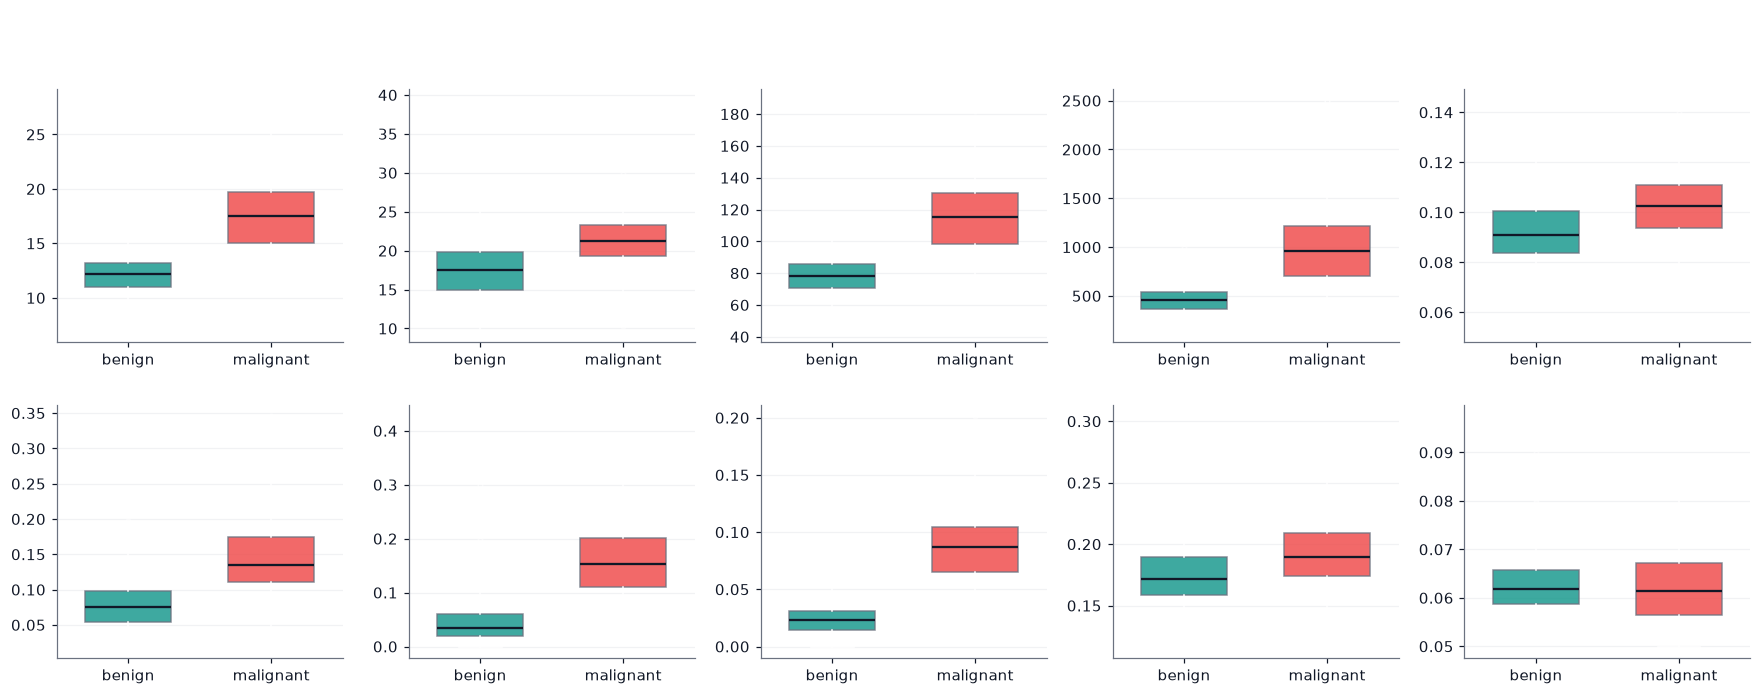

Skewness of the 30 features: median 1.39 | features with skewness > 1: 22 | largest: area_se 5.71


In [6]:
fig, axes = plt.subplots(2, 5, figsize=(16, 6.2))
for ax, m in zip(axes.ravel(), MEASUREMENTS):
    col = FEATURE_NAMES.index(f"{m}_mean")
    data = [X_dev[y_dev == 0, col], X_dev[y_dev == 1, col]]
    bp = ax.boxplot(data, patch_artist=True, widths=0.6, showfliers=True, flierprops={"markersize": 3, "alpha": 0.5},
                    medianprops={"color": COLORS["dark"], "linewidth": 1.5})
    for patch, color in zip(bp["boxes"], [CLASS_COLORS["benign"], CLASS_COLORS["malignant"]]):
        patch.set_facecolor(color); patch.set_alpha(0.8); patch.set_edgecolor(COLORS["gray"])
    ax.set_xticks([1, 2]); ax.set_xticklabels(["benign", "malignant"]); ax.set_title(f"{m}_mean", fontsize=10.5); ax.grid(axis="x", visible=False)
fig.suptitle(f"Distribution of the ten 'mean' measurements by diagnosis (development set, n = {len(y_dev)})", fontsize=13, fontweight="bold", x=0.01, ha="left", y=1.01)
finish(fig, "01_feature_distributions")

def skewness(x):
    x = np.asarray(x, dtype=float)
    return float(np.mean((x - x.mean()) ** 3) / (x.std() ** 3 + 1e-12))
skew = pd.Series({n: skewness(X_dev[:, i]) for i, n in enumerate(FEATURE_NAMES)})
print("Skewness of the 30 features: median", round(float(skew.median()), 2), "| features with skewness > 1:", int((skew > 1).sum()), "| largest:", skew.idxmax(), round(float(skew.max()), 2))

### 6.2 Univariate discrimination: AUC of every feature

For each feature we compute the AUC for malignant against benign, $\text{AUC} = \mathbb{P}(X^{+} > X^{-}) + \tfrac{1}{2}\mathbb{P}(X^{+} = X^{-})$ (Notebook 07; it is computed from ranks, so it is invariant to monotone transformations of the feature). Values near 0.5 mean no information; near 1 (malignant has larger values) or near 0 (smaller values) mean strong discrimination. To compare strength regardless of direction, we plot $\max(\text{AUC}, 1 - \text{AUC})$.

**Warning.** This analysis uses the **labels**; it is legitimate *only because* it uses the development set and is for exploration. If we used it to *select features* for a model, the selection would have to be repeated inside each cross-validation fold (Notebook 07, Section 6).

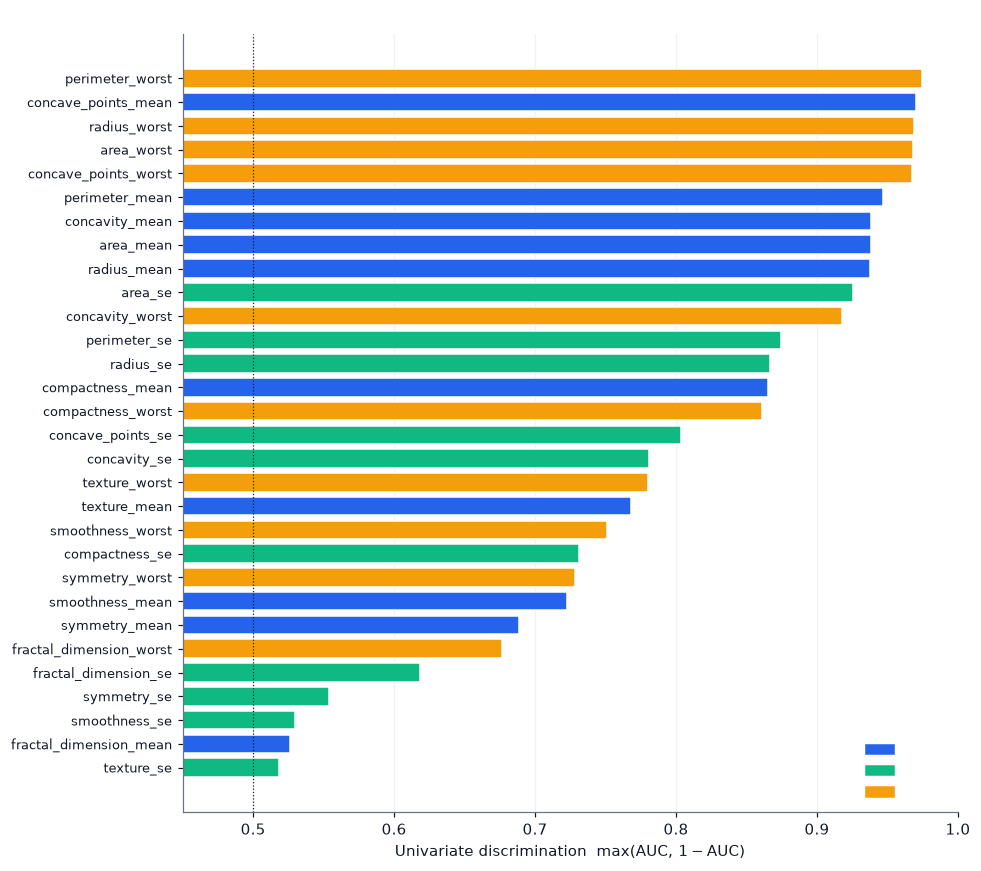

Strongest single features: ['perimeter_worst', 'concave_points_mean', 'radius_worst', 'area_worst', 'concave_points_worst']
Weakest single features  : ['texture_se', 'fractal_dimension_mean', 'smoothness_se', 'symmetry_se', 'fractal_dimension_se']


In [7]:
def average_ranks(values):
    order = np.argsort(values, kind="stable"); ranks = np.empty(len(values)); s = np.asarray(values)[order]
    i = 0
    while i < len(values):
        j = i
        while j + 1 < len(values) and s[j + 1] == s[i]:
            j += 1
        ranks[order[i:j + 1]] = (i + j) / 2 + 1; i = j + 1
    return ranks

def auc_rank(y_true, score):
    """AUC = P(score of a positive > score of a negative) via average ranks (Mann-Whitney)."""
    y_true = np.asarray(y_true).astype(bool)
    n_pos, n_neg = y_true.sum(), (~y_true).sum()
    ranks = average_ranks(np.asarray(score, dtype=float))
    return float((ranks[y_true].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))

uni_auc = pd.Series({n: auc_rank(y_dev, X_dev[:, i]) for i, n in enumerate(FEATURE_NAMES)})
strength = np.maximum(uni_auc, 1 - uni_auc).sort_values()

fig, ax = plt.subplots(figsize=(9, 8))
colors = [GROUP_COLORS[n.split("_")[-1]] for n in strength.index]                        # the suffix: mean, se, or worst
ax.barh(range(len(strength)), strength.values, color=colors, edgecolor="white", height=0.78)
ax.set_yticks(range(len(strength))); ax.set_yticklabels(strength.index, fontsize=8.5)
ax.axvline(0.5, color=COLORS["dark"], linewidth=0.8, linestyle=":")
ax.set_xlim(0.45, 1.0); ax.set_xlabel(r"Univariate discrimination  $\max(\mathrm{AUC},\, 1-\mathrm{AUC})$")
ax.set_title("Which single features separate malignant from benign? (development set)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=n) for n, c in GROUP_COLORS.items()], loc="lower right", title="statistic"); ax.grid(axis="y", visible=False)
finish(fig, "02_univariate_auc")
print("Strongest single features:", strength.index[::-1][:5].tolist())
print("Weakest single features  :", strength.index[:5].tolist())

Typically the **size and shape-irregularity** features (radius, perimeter, area, concavity, concave points) of the *mean* and especially the *worst* values are very discriminative on their own, while texture-like, symmetry, and fractal-dimension measurements are weaker, and **standard-error** features of several measurements carry little individual information. A single feature already gives an AUC around 0.9 or more — this task is easy, which is why evaluation quality, not raw accuracy, decides the scientific value of the work.

### 6.3 Redundancy: the features are strongly correlated

The radius, perimeter, and area of a nucleus are geometrically related ($\text{perimeter} \approx 2\pi r$, $\text{area} \approx \pi r^2$), and the mean and worst values of a measurement move together. High correlation (**multicollinearity**) makes the individual coefficients of a linear model unstable (Notebook 05) and splits importance between features (Section 18).

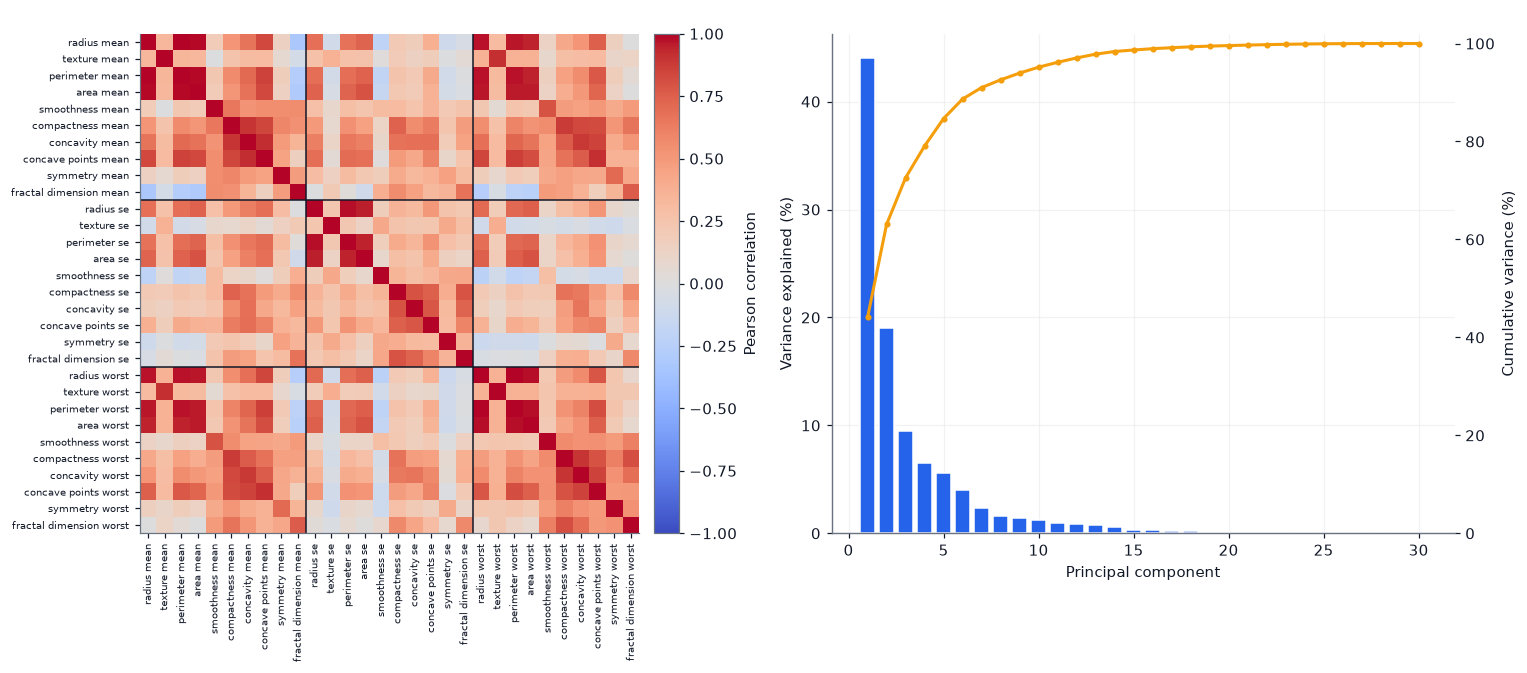

Feature pairs with |r| > 0.9: 21 of 435 | with |r| > 0.95: 15
Components needed to explain 90% / 95% / 99% of the variance: [7, 10, 17]


In [8]:
corr = np.corrcoef(X_dev, rowvar=False)
fig, axes = plt.subplots(1, 2, figsize=(15, 6.2), gridspec_kw={"width_ratios": [1.15, 1]})
im = axes[0].imshow(corr, cmap="coolwarm", vmin=-1, vmax=1); axes[0].grid(False)
axes[0].set_xticks(range(0, 30, 1)); axes[0].set_xticklabels([n.replace("_", " ") for n in FEATURE_NAMES], rotation=90, fontsize=6.3)
axes[0].set_yticks(range(0, 30, 1)); axes[0].set_yticklabels([n.replace("_", " ") for n in FEATURE_NAMES], fontsize=6.3)
for b in (9.5, 19.5):
    axes[0].axhline(b, color=COLORS["dark"], linewidth=1); axes[0].axvline(b, color=COLORS["dark"], linewidth=1)
fig.colorbar(im, ax=axes[0], fraction=0.046, pad=0.02, label="Pearson correlation")
axes[0].set_title("Feature correlations (blocks: mean | se | worst)")

# PCA of the standardized development data: how many dimensions are really needed?
Xs = (X_dev - X_dev.mean(axis=0)) / X_dev.std(axis=0)
U, S, Vt = np.linalg.svd(Xs, full_matrices=False)
explained = S**2 / np.sum(S**2)
axes[1].bar(np.arange(1, 31), explained * 100, color=COLORS["blue"], edgecolor="white", label="per component")
ax2 = axes[1].twinx(); ax2.plot(np.arange(1, 31), np.cumsum(explained) * 100, color=COLORS["orange"], marker="o", markersize=3, label="cumulative"); ax2.grid(False)
ax2.set_ylabel("Cumulative variance (%)"); ax2.set_ylim(0, 102)
axes[1].set_xlabel("Principal component"); axes[1].set_ylabel("Variance explained (%)"); axes[1].set_title("Scree plot of the standardized features")
finish(fig, "03_correlation_and_pca")
iu = np.triu_indices(30, 1)
print(f"Feature pairs with |r| > 0.9: {int(np.sum(np.abs(corr[iu]) > 0.9))} of {len(iu[0])} | with |r| > 0.95: {int(np.sum(np.abs(corr[iu]) > 0.95))}")
print(f"Components needed to explain 90% / 95% / 99% of the variance:", [int(np.searchsorted(np.cumsum(explained), f) + 1) for f in (0.9, 0.95, 0.99)])

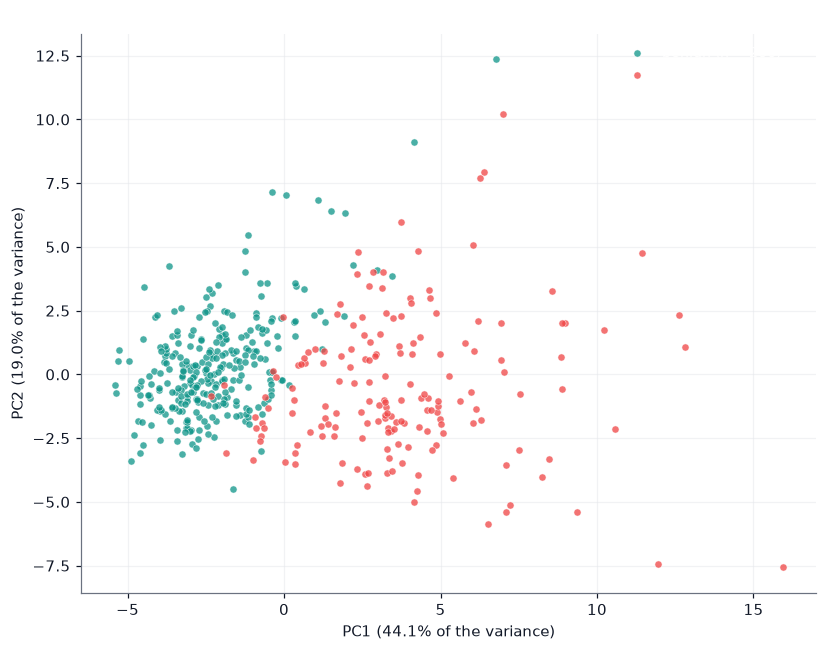

In [9]:
# The data in two dimensions (PCA scores of the development set).
scores_pc = Xs @ Vt[:2].T
fig, ax = plt.subplots(figsize=(7.6, 6.0))
for label, name in [(0, "benign"), (1, "malignant")]:
    sel = y_dev == label
    ax.scatter(scores_pc[sel, 0], scores_pc[sel, 1], s=22, alpha=0.75, color=CLASS_COLORS[name], edgecolor="white", linewidth=0.4, label=f"{name} (n = {int(sel.sum())})")
ax.set_xlabel(f"PC1 ({100 * explained[0]:.1f}% of the variance)"); ax.set_ylabel(f"PC2 ({100 * explained[1]:.1f}% of the variance)")
ax.set_title("The two classes in the first two principal components"); ax.legend()
finish(fig, "04_pca_scatter")

Two principal components already capture most of the variance, and the classes occupy largely **different regions with a zone of overlap**. The overlap is where the clinical difficulty lies (borderline cases), and where the quality of the probabilities will matter.

## 7. Preprocessing decisions

All preprocessing is a **pipeline fitted on the training data of each fold** (rule 3):

1. **Optional $\log(1+x)$ transform.** Many features are right-skewed (areas, standard errors), and a logarithm makes them more symmetric, which suits linear and neural models. It has no fitted parameters but is a *decision* that we make with the development data (below).
2. **Standardization:** $x' = (x - \mu_{\text{train}})/\sigma_{\text{train}}$ (Notebooks 03 and 05).

We implement the pipeline as a small class whose `fit` uses only the training samples it receives.

In [10]:
class Preprocessor:
    """Optional log(1 + x) followed by standardization; every statistic is learned from the data given to fit()."""
    def __init__(self, log_transform=True):
        self.log_transform = log_transform
    def _t(self, X):
        return np.log1p(X) if self.log_transform else np.asarray(X, dtype=np.float64)
    def fit(self, X):
        T = self._t(X); self.mu, self.sd = T.mean(axis=0), T.std(axis=0) + 1e-12
        return self
    def transform(self, X):
        return (self._t(X) - self.mu) / self.sd
    def fit_transform(self, X):
        return self.fit(X).transform(X)

demo = Preprocessor(True).fit(X_dev)
Xt = demo.transform(X_dev)
print("After the pipeline (development data): mean of the feature means", round(float(Xt.mean()), 6), "| mean of the feature variances", round(float(Xt.var(axis=0).mean()), 4))
print("Skewness after log1p: median", round(float(np.median([skewness(Xt[:, i]) for i in range(30)])), 2), "(before:", round(float(skew.median()), 2), ")")
print("Test samples are transformed with the DEVELOPMENT statistics:", np.round(Preprocessor(True).fit(X_dev).transform(X_test).mean(axis=0)[:3], 3), "(not exactly 0, as expected)")

After the pipeline (development data): mean of the feature means -0.0 | mean of the feature variances 1.0
Skewness after log1p: median 0.95 (before: 1.39 )
Test samples are transformed with the DEVELOPMENT statistics: [0.049 0.039 0.052] (not exactly 0, as expected)


# Part C — Methods: the mathematics we will rely on

## 8. Logistic regression, scoring rules, calibration, and decision theory

### 8.1 Logistic regression and Newton's method

The baseline model is **logistic regression**: $\hat{p}(x) = \sigma(w_0 + x^{\top}w)$ with $\sigma(t) = 1/(1+e^{-t})$. For $n$ training samples, the (penalized) negative log-likelihood is

$$
L(w) = -\sum_{i=1}^{n}\Big[y_i\ln \hat{p}_i + (1-y_i)\ln(1-\hat{p}_i)\Big] + \frac{\lambda}{2}\lVert w_{1:d}\rVert^2 ,
$$

where the **intercept $w_0$ is not penalized** and $\lambda \ge 0$ is the L2 penalty (a Gaussian prior on the weights, Notebook 06). With $X$ the design matrix (a column of ones followed by the standardized features), $p$ the vector of predicted probabilities, and $R = \operatorname{diag}(0, \lambda, \dots, \lambda)$:

$$
\nabla L = X^{\top}(p - y) + Rw, \qquad
\nabla^2 L = X^{\top}WX + R, \qquad W = \operatorname{diag}\big(p_i(1-p_i)\big).
$$

The gradient is "prediction minus target", exactly as for softmax and cross-entropy (Notebook 04). The Hessian is positive semi-definite (and positive definite for $\lambda > 0$), so $L$ is **convex** and has a unique global minimum. **Newton's method** (also called *iteratively reweighted least squares*, IRLS) uses the second-order information:

$$
w \leftarrow w - \big(\nabla^2 L\big)^{-1}\nabla L ,
$$

and converges in a handful of iterations (quadratically near the optimum), without a learning rate. We implement it, check the gradient against finite differences, and compare it with plain gradient descent.

In [11]:
def sigmoid(t):
    t = np.clip(t, -35, 35)
    return 1.0 / (1.0 + np.exp(-t))

def logit(p, eps=1e-6):
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p))

def logistic_objective(w, Xb, y, lam):
    z = Xb @ w
    return float(np.sum(np.logaddexp(0, z) - y * z) + 0.5 * lam * np.sum(w[1:] ** 2))     # stable form of the negative log-likelihood

def logistic_gradient(w, Xb, y, lam):
    R = np.r_[0.0, np.full(len(w) - 1, lam)]
    return Xb.T @ (sigmoid(Xb @ w) - y) + R * w

def logistic_fit(X, y, lam=1.0, max_iter=50, tol=1e-9, history=False):
    """L2-penalized logistic regression by Newton's method (IRLS); the intercept is not penalized."""
    Xb = np.column_stack([np.ones(len(X)), X])
    w = np.zeros(Xb.shape[1]); R = np.diag(np.r_[0.0, np.full(Xb.shape[1] - 1, lam)])
    grad_norms = []
    for _ in range(max_iter):
        p = sigmoid(Xb @ w)
        g = Xb.T @ (p - y) + R @ w
        grad_norms.append(float(np.linalg.norm(g)))
        H = Xb.T @ (Xb * (p * (1 - p))[:, None]) + R + 1e-10 * np.eye(len(w))
        step = np.linalg.solve(H, g)
        w = w - step
        if np.linalg.norm(step) < tol:
            break
    return (w, grad_norms) if history else w

def logistic_proba(w, X):
    return sigmoid(w[0] + X @ w[1:])

# --- Verification on the (standardized) development data -----------------------------------------------------
Xd_std = Preprocessor(True).fit_transform(X_dev)
Xb_dev = np.column_stack([np.ones(len(Xd_std)), Xd_std])
w_newton, grad_norms = logistic_fit(Xd_std, y_dev, lam=1.0, history=True)
print("Newton's method: gradient norm per iteration:", [f"{g:.1e}" for g in grad_norms])

# (1) the analytic gradient agrees with finite differences
rg = np.random.default_rng(0); w_probe = rg.normal(0, 0.3, size=Xb_dev.shape[1])
numeric = np.array([(logistic_objective(w_probe + e, Xb_dev, y_dev, 1.0) - logistic_objective(w_probe - e, Xb_dev, y_dev, 1.0)) / 2e-6
                    for e in np.eye(len(w_probe)) * 1e-6])
analytic = logistic_gradient(w_probe, Xb_dev, y_dev, 1.0)
rel = np.linalg.norm(analytic - numeric) / (np.linalg.norm(analytic) + np.linalg.norm(numeric))
print(f"Gradient check (analytic against finite differences): relative error {rel:.2e}")
assert rel < 1e-6

# (2) plain gradient descent reaches the same solution, but needs thousands of steps
w_gd = np.zeros_like(w_newton); lr = 1.0 / (0.25 * np.linalg.norm(Xb_dev, 2) ** 2 + 1.0); steps = 0
while np.linalg.norm(logistic_gradient(w_gd, Xb_dev, y_dev, 1.0)) > 1e-4 and steps < 200000:
    w_gd -= lr * logistic_gradient(w_gd, Xb_dev, y_dev, 1.0); steps += 1
print(f"Gradient descent: {steps} steps to reach a gradient norm of 1e-4 | maximum |w_GD - w_Newton| = {np.abs(w_gd - w_newton).max():.2e}")
assert np.linalg.norm(logistic_gradient(w_newton, Xb_dev, y_dev, 1.0)) < 1e-6

Newton's method: gradient norm per iteration: ['6.7e+02', '1.9e+02', '7.2e+01', '2.9e+01', '1.1e+01', '3.4e+00', '5.9e-01', '2.4e-02', '4.7e-05', '4.7e-10']
Gradient check (analytic against finite differences): relative error 8.29e-11
Gradient descent: 12356 steps to reach a gradient norm of 1e-4 | maximum |w_GD - w_Newton| = 4.20e-05


Newton's method needs only a few iterations (the gradient norm collapses quadratically), while gradient descent needs thousands: second-order information is worth its price for a convex problem with 31 parameters. (For a neural network with thousands of parameters the Hessian is too expensive and non-convex, which is why Adam and its relatives are used instead; Notebook 06.)

### 8.2 Proper scoring rules: judging probabilities

A classifier that outputs probabilities should be judged by a **proper scoring rule**: a loss whose *expected value is minimized when the predicted probability equals the true probability*. The two we use:

$$
\text{log loss} = -\frac{1}{n}\sum_i\big[y_i\ln\hat{p}_i + (1-y_i)\ln(1-\hat{p}_i)\big], \qquad
\text{Brier score} = \frac{1}{n}\sum_i(\hat{p}_i - y_i)^2 .
$$

If the true probability of a malignant diagnosis for a given patient profile is $p$, and the model predicts $q$, the expected losses are

$$
\mathbb{E}[\text{log loss}] = -\big[p\ln q + (1-p)\ln(1-q)\big], \qquad
\mathbb{E}[\text{Brier}] = p(1-q)^2 + (1-p)q^2 ,
$$

and setting the derivative with respect to $q$ to zero gives $q = p$ for both: **honesty is optimal**. The AUC is *not* proper: it depends only on the ranking and cannot distinguish a calibrated model from an overconfident one (Notebook 07). Log loss punishes confident mistakes far more severely than the Brier score, which is why we use it as the primary selection metric.

True probability 0.3: minimum of the expected log loss at q = 0.300, of the expected Brier score at q = 0.300


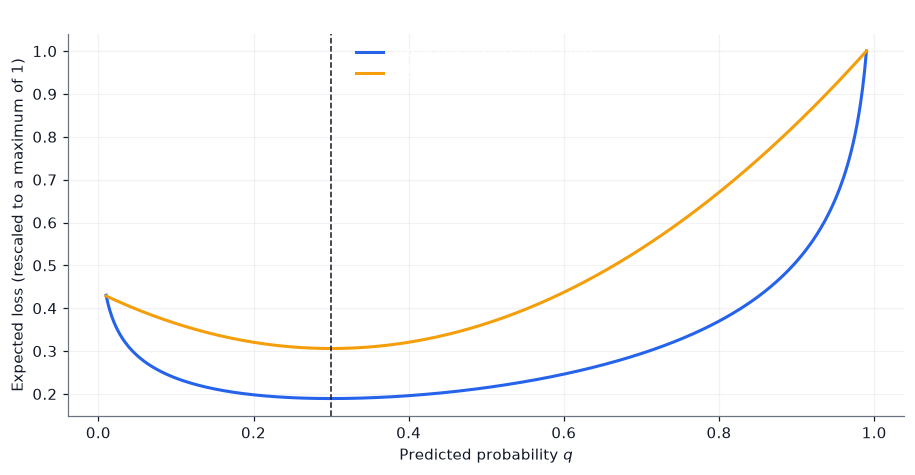

In [12]:
p_true = 0.3
q = np.linspace(0.01, 0.99, 400)
exp_log = -(p_true * np.log(q) + (1 - p_true) * np.log(1 - q))
exp_brier = p_true * (1 - q) ** 2 + (1 - p_true) * q ** 2
print(f"True probability {p_true}: minimum of the expected log loss at q = {q[np.argmin(exp_log)]:.3f}, of the expected Brier score at q = {q[np.argmin(exp_brier)]:.3f}")

fig, ax = plt.subplots(figsize=(8.4, 4.4))
ax.plot(q, exp_log / exp_log.max(), color=COLORS["blue"], label="expected log loss (rescaled)")
ax.plot(q, exp_brier / exp_brier.max(), color=COLORS["orange"], label="expected Brier score (rescaled)")
ax.axvline(p_true, color=COLORS["dark"], linestyle="--", linewidth=1); ax.annotate("true probability", (p_true, 0.95), xytext=(5, 0), textcoords="offset points", fontsize=9)
ax.set_xlabel("Predicted probability $q$"); ax.set_ylabel("Expected loss (rescaled to a maximum of 1)"); ax.set_title("Proper scoring rules are minimized by the true probability"); ax.legend(loc="upper center")
finish(fig, "05_proper_scoring_rules")

### 8.3 Calibration and Platt scaling

A model is **calibrated** if, among the samples with predicted probability $\hat{p}$, a fraction $\hat{p}$ are positive (Notebook 07). Neural networks trained with cross-entropy are often *overconfident*. **Platt scaling** fixes a monotone miscalibration with two parameters: replace the model output by

$$
\hat{p}_{\text{cal}} = \sigma\big(a\cdot \operatorname{logit}(\hat{p}) + b\big),
$$

where $(a, b)$ are fitted by logistic regression on **held-out** predictions (here: out-of-fold development predictions). Since $\sigma(a \cdot \text{logit}(\cdot) + b)$ is monotone in $\hat{p}$ (for $a > 0$), **the ranking and hence the AUC do not change**; only the probabilities do. We check it on a synthetic overconfident model: its probabilities are $\sigma(3\cdot t)$ where $t$ is the true logit, so the true correction is $a = 1/3$, $b = 0$.

In [13]:
def reliability_bins(y_true, prob, n_bins=10):
    y_true, prob = np.asarray(y_true, dtype=float), np.asarray(prob, dtype=float)
    which = np.clip(np.digitize(prob, np.linspace(0, 1, n_bins + 1)[1:-1]), 0, n_bins - 1)
    return np.array([(prob[which == b].mean(), y_true[which == b].mean(), int((which == b).sum())) for b in range(n_bins) if np.any(which == b)])

def log_loss(y_true, prob, eps=1e-12):
    prob = np.clip(np.asarray(prob, dtype=float), eps, 1 - eps)
    return float(-np.mean(y_true * np.log(prob) + (1 - y_true) * np.log(1 - prob)))

def brier_score(y_true, prob):
    return float(np.mean((np.asarray(prob) - np.asarray(y_true)) ** 2))

def expected_calibration_error(y_true, prob, n_bins=10):
    rel = reliability_bins(y_true, prob, n_bins)
    return float(np.sum(rel[:, 2] / rel[:, 2].sum() * np.abs(rel[:, 1] - rel[:, 0])))

def platt_fit(prob, y_true):
    """(a, b) of  sigma(a * logit(p) + b)  fitted by (unpenalized) logistic regression on held-out predictions."""
    w = logistic_fit(logit(prob)[:, None], y_true, lam=1e-6)
    return float(w[1]), float(w[0])

def platt_apply(prob, params):
    a, b = params
    return sigmoid(a * logit(prob) + b)

# Synthetic check: a model whose logits are 3x too extreme.
rg = np.random.default_rng(1); n_syn = 20000
true_logit = rg.normal(0, 1.6, size=n_syn); y_syn = (rg.random(n_syn) < sigmoid(true_logit)).astype(float)
p_over = sigmoid(3.0 * true_logit)
a_hat, b_hat = platt_fit(p_over, y_syn)
p_fixed = platt_apply(p_over, (a_hat, b_hat))
print(f"Platt parameters recovered: a = {a_hat:.3f} (true 0.333), b = {b_hat:.3f} (true 0)")
print(f"Brier score: overconfident {brier_score(y_syn, p_over):.4f} -> calibrated {brier_score(y_syn, p_fixed):.4f} | ECE: {expected_calibration_error(y_syn, p_over):.4f} -> {expected_calibration_error(y_syn, p_fixed):.4f}")
print(f"AUC unchanged by the monotone transformation: {auc_rank(y_syn, p_over):.4f} vs {auc_rank(y_syn, p_fixed):.4f}")
assert abs(a_hat - 1 / 3) < 0.03 and abs(b_hat) < 0.05

Platt parameters recovered: a = 0.338 (true 0.333), b = 0.013 (true 0)
Brier score: overconfident 0.1953 -> calibrated 0.1702 | ECE: 0.1452 -> 0.0071
AUC unchanged by the monotone transformation: 0.8261 vs 0.8261


### 8.4 Decision theory and net benefit

For a calibrated probability, the cost-minimizing rule is to call a sample malignant when $\hat{p} \ge p^{*} = c_{FP}/(c_{FP}+c_{FN})$ (Section 2.3). **Decision-curve analysis** (Vickers and Elkin, 2006) asks the *clinical* question: *compared with treating everyone, or no one, is it useful to base the decision on the model?* For a threshold probability $t$ — the probability above which the clinician would act — the **net benefit** is

$$
\text{NB}(t) = \frac{TP}{n} - \frac{FP}{n}\cdot\frac{t}{1-t},
$$

where $t/(1-t)$ is the **exchange rate** between false and true positives: acting on a false positive costs $t/(1-t)$ of the benefit of acting on a true positive. Two reference strategies: **treat none** ($\text{NB} = 0$) and **treat all** ($\text{NB} = \pi - (1-\pi)\,t/(1-t)$ with $\pi$ the prevalence). The link with our costs is exact: if $c_{FP}/c_{FN} = t/(1-t)$, i.e. $t = p^{*}$,

$$
\text{NB}(t) = \pi - \frac{\text{expected cost per patient}}{c_{FN}},
$$

because $\pi - FN/n = TP/n$. **Maximizing the net benefit at $t = p^{*}$ is the same as minimizing the expected cost.** We verify the identity numerically.

In [14]:
def net_benefit(y_true, prob, t):
    y_true = np.asarray(y_true); pred = np.asarray(prob) >= t
    n = len(y_true); tp, fp = np.sum(pred & (y_true == 1)), np.sum(pred & (y_true == 0))
    return tp / n - fp / n * t / (1 - t)

def expected_cost(y_true, prob, t, c_fn=COST_FN, c_fp=COST_FP):
    y_true = np.asarray(y_true); pred = np.asarray(prob) >= t
    return (c_fn * np.sum(~pred & (y_true == 1)) + c_fp * np.sum(pred & (y_true == 0))) / len(y_true)

# Identity: NB(p*) = prevalence - expected cost / c_FN, for any predicted probabilities.
rg = np.random.default_rng(2); y_chk = (rg.random(5000) < 0.37).astype(int); p_chk = np.clip(0.3 * y_chk + rg.beta(2, 3, size=5000) * 0.7, 0, 1)
lhs = net_benefit(y_chk, p_chk, P_STAR)
rhs = y_chk.mean() - expected_cost(y_chk, p_chk, P_STAR) / COST_FN
print(f"NB(p*) = {lhs:.6f} | prevalence - cost / c_FN = {rhs:.6f}")
assert abs(lhs - rhs) < 1e-12

# The cost-minimizing threshold for CALIBRATED probabilities is p*: check by scanning thresholds.
ts = np.linspace(0.02, 0.98, 481)
p_cal_demo = sigmoid(true_logit[:20000]); y_cal_demo = y_syn[:20000]
costs = [expected_cost(y_cal_demo, p_cal_demo, t) for t in ts]
print(f"Calibrated synthetic model: the cost is minimal at t = {ts[int(np.argmin(costs))]:.3f} (theory: p* = {P_STAR:.3f})")

NB(p*) = 0.278920 | prevalence - cost / c_FN = 0.278920
Calibrated synthetic model: the cost is minimal at t = 0.170 (theory: p* = 0.167)


### 8.5 Random search for hyperparameters

A neural network has hyperparameters (width, depth, dropout, L2 weight, learning rate, ...). **Grid search** spends most evaluations on unimportant combinations when only a few hyperparameters matter; **random search** (Bergstra and Bengio, 2012) draws configurations at random and explores more distinct values of every hyperparameter. If a fraction $q$ of the search space is "good", the probability that $N$ random draws contain at least one good configuration is

$$
1 - (1 - q)^{N} .
$$

For $N = 12$ draws, there is a $72\%$ chance of hitting the best 10% of the space, and a $46\%$ chance for the best 5%. With so few draws, the selected configuration is **not** the optimum, only a good one, and its cross-validated score is optimistically biased (the winner's curse of Notebook 07) — which is why the final report uses the untouched test set.

### 8.6 Intervals and tests (from Notebook 07)

We reuse: **Wilson** intervals for proportions (sensitivity, specificity, accuracy), the **percentile bootstrap** for AUC and other statistics, **McNemar's exact test** for paired predictions on the same samples, and the **corrected resampled $t$-test** (Nadeau and Bengio, 2003) for paired differences between cross-validation folds:

$$
t = \frac{\bar{d}}{\sqrt{\big(\tfrac{1}{J} + \tfrac{n_{\text{test}}}{n_{\text{train}}}\big)\,s_d^2}} .
$$

In [15]:
def wilson_interval(k, n, z=1.959964):
    if n == 0:
        return float("nan"), float("nan")
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return max(0.0, centre - half), min(1.0, centre + half)

def binary_metrics(y_true, pred):
    y_true, pred = np.asarray(y_true).astype(bool), np.asarray(pred).astype(bool)
    tp, fp, fn, tn = int(np.sum(y_true & pred)), int(np.sum(~y_true & pred)), int(np.sum(y_true & ~pred)), int(np.sum(~y_true & ~pred))
    div = lambda a, b: a / b if b else float("nan")
    return {"TP": tp, "FP": fp, "FN": fn, "TN": tn, "sensitivity": div(tp, tp + fn), "specificity": div(tn, tn + fp),
            "PPV": div(tp, tp + fp), "NPV": div(tn, tn + fn), "accuracy": (tp + tn) / len(y_true)}

def roc_curve_np(y_true, score):
    y_true = np.asarray(y_true).astype(bool)
    order = np.argsort(-score, kind="stable"); s, yt = np.asarray(score)[order], y_true[order]
    tps, fps = np.cumsum(yt), np.cumsum(~yt)
    distinct = np.r_[np.flatnonzero(np.diff(s)), len(s) - 1]
    return np.r_[0.0, fps[distinct] / fps[-1]], np.r_[0.0, tps[distinct] / tps[-1]]

def pr_curve_np(y_true, score):
    y_true = np.asarray(y_true).astype(bool)
    order = np.argsort(-score, kind="stable"); s, yt = np.asarray(score)[order], y_true[order]
    tps, fps = np.cumsum(yt), np.cumsum(~yt)
    distinct = np.r_[np.flatnonzero(np.diff(s)), len(s) - 1]
    return np.r_[1.0, tps[distinct] / (tps[distinct] + fps[distinct])], np.r_[0.0, tps[distinct] / tps[-1]]

def average_precision(y_true, score):
    prec, rec = pr_curve_np(y_true, score)
    return float(np.sum((rec[1:] - rec[:-1]) * prec[1:]))

def bootstrap_ci(metric_fn, y_true, prob, n_boot=N_BOOT, seed=0):
    r = np.random.default_rng(seed); n = len(y_true); vals = []
    for _ in range(n_boot):
        idx = r.integers(0, n, size=n)
        if y_true[idx].min() == y_true[idx].max():
            continue
        vals.append(metric_fn(y_true[idx], prob[idx]))
    return np.percentile(vals, [2.5, 97.5])

def mcnemar_exact(correct_a, correct_b):
    correct_a, correct_b = np.asarray(correct_a, dtype=bool), np.asarray(correct_b, dtype=bool)
    b, c = int(np.sum(correct_a & ~correct_b)), int(np.sum(~correct_a & correct_b)); n = b + c
    if n == 0:
        return b, c, 1.0
    return b, c, min(1.0, 2 * sum(comb(n, i) for i in range(min(b, c) + 1)) / 2**n)

def student_t_two_sided_p(t_stat, df):
    norm = math.exp(lgamma((df + 1) / 2) - lgamma(df / 2)) / math.sqrt(df * math.pi)
    xs = np.linspace(abs(t_stat), abs(t_stat) + 400.0, 400001)
    integrate = getattr(np, "trapezoid", None) or np.trapz
    return float(min(1.0, 2 * integrate(norm * (1 + xs**2 / df) ** (-(df + 1) / 2), xs)))

def corrected_resampled_ttest(differences, n_train, n_test):
    d = np.asarray(differences, dtype=float); J = len(d); var = d.var(ddof=1)
    if var == 0:
        return (float("inf") if d.mean() != 0 else 0.0), (0.0 if d.mean() != 0 else 1.0)
    t_stat = d.mean() / math.sqrt((1 / J + n_test / n_train) * var)
    return float(t_stat), student_t_two_sided_p(t_stat, J - 1)

def stratified_kfold(y, n_splits, seed):
    r = np.random.default_rng(seed); folds = [[] for _ in range(n_splits)]
    for c in np.unique(y):
        for i, j in enumerate(r.permutation(np.flatnonzero(y == c))):
            folds[i % n_splits].append(j)
    all_idx = np.arange(len(y))
    for f in folds:
        test = np.array(sorted(f), dtype=int)
        yield np.setdiff1d(all_idx, test), test

print("AUC check:", round(auc_rank([0, 0, 1, 1, 1], [0.1, 0.6, 0.4, 0.8, 0.6]), 4), "(expected 0.75: 4.5 of the 6 positive-negative pairs, counting one tie as 1/2)")
print("Probability that 12 random draws contain a configuration from the best 10% of the space:", round(1 - 0.9**12, 3))

AUC check: 0.75 (expected 0.75: 4.5 of the 6 positive-negative pairs, counting one tie as 1/2)
Probability that 12 random draws contain a configuration from the best 10% of the space: 0.718


# Part D — Modelling

## 9. Preprocessing decision: is the logarithm useful?

We decide whether to apply $\log(1+x)$ using **cross-validation on the development set** with the logistic-regression baseline ($\lambda = 1$), comparing the mean log loss over the 5 folds (the decision is made with the development data only, and the preprocessing is refitted in every fold).

In [16]:
def cv_logreg_log_loss(use_log, lam=1.0, n_splits=5, seed=SEED):
    losses = []
    for tr_i, te_i in stratified_kfold(y_dev, n_splits, seed):
        prep = Preprocessor(use_log).fit(X_dev[tr_i])
        w = logistic_fit(prep.transform(X_dev[tr_i]), y_dev[tr_i], lam)
        losses.append(log_loss(y_dev[te_i], logistic_proba(w, prep.transform(X_dev[te_i]))))
    return np.array(losses)

loss_log, loss_raw = cv_logreg_log_loss(True), cv_logreg_log_loss(False)
print(f"5-fold CV log loss of logistic regression:  with log1p {loss_log.mean():.4f} \u00b1 {loss_log.std():.4f} | without {loss_raw.mean():.4f} \u00b1 {loss_raw.std():.4f}")
USE_LOG = bool(loss_log.mean() < loss_raw.mean())
print("Decision (lower mean log loss):", "apply log1p + standardization" if USE_LOG else "standardization only")

5-fold CV log loss of logistic regression:  with log1p 0.0739 ± 0.0308 | without 0.0726 ± 0.0305
Decision (lower mean log loss): standardization only


## 10. Baselines

Rule 4: before any neural network, we need honest baselines.

1. **Majority class:** predict the training prevalence for everybody. Its log loss is the binary entropy of the prevalence, $H(\pi) = -\pi\ln\pi-(1-\pi)\ln(1-\pi)$, the benchmark of "no information".
2. **Logistic regression** (Section 8.1), with the penalty $\lambda$ chosen by an **inner** 3-fold cross-validation (grid $10^{-2}$ to $10^{3}$), refitting the preprocessing in every inner fold.
3. **$k$-nearest neighbours** on the standardized features: the predicted probability is $(m + 0.5)/(k + 1)$, with $m$ the number of malignant neighbours among the $k$ nearest (the 0.5 smoothing avoids probabilities of exactly 0 or 1, which would give an infinite log loss); $k$ chosen by the same inner cross-validation.

The inner cross-validation is part of the model: for each *outer* training set, hyperparameters are chosen **without** the outer test fold (nested cross-validation, Notebook 07).

In [17]:
def knn_proba(Xtr, ytr, Xq, k):
    d2 = (Xq**2).sum(1)[:, None] + (Xtr**2).sum(1)[None, :] - 2 * Xq @ Xtr.T
    idx = np.argsort(d2, axis=1)[:, :k]
    return (ytr[idx].sum(axis=1) + 0.5) / (k + 1)

def inner_tune(predict_fn, grid, X_raw, y, use_log, seed, n_splits=3):
    """Choose the hyperparameter with the lowest mean log loss over inner folds (preprocessing refitted in every inner fold)."""
    scores = {g: [] for g in grid}
    for itr, ite in stratified_kfold(y, n_splits, seed):
        prep = Preprocessor(use_log).fit(X_raw[itr]); Xa, Xb = prep.transform(X_raw[itr]), prep.transform(X_raw[ite])
        for g in grid:
            scores[g].append(log_loss(y[ite], predict_fn(Xa, y[itr], Xb, g)))
    return min(grid, key=lambda g: np.mean(scores[g]))

logreg_predict = lambda Xa, ya, Xb, lam: logistic_proba(logistic_fit(Xa, ya, lam), Xb)
LAMBDA_GRID = (0.01, 0.1, 1.0, 10.0, 100.0, 1000.0)
K_GRID = (1, 3, 5, 9, 15, 25)

prevalence = y_dev.mean()
print(f"Majority-class log loss = binary entropy of the prevalence ({prevalence:.3f}): {-(prevalence * np.log(prevalence) + (1 - prevalence) * np.log(1 - prevalence)):.4f}")
lam_dev = inner_tune(logreg_predict, LAMBDA_GRID, X_dev, y_dev, USE_LOG, SEED)
k_dev = inner_tune(knn_proba, K_GRID, X_dev, y_dev, USE_LOG, SEED)
print("Penalty and number of neighbours selected by inner cross-validation on the whole development set:", lam_dev, "and", k_dev)

Majority-class log loss = binary entropy of the prevalence (0.373): 0.6604
Penalty and number of neighbours selected by inner cross-validation on the whole development set: 1.0 and 15


## 11. The neural network: a regularized MLP for small tabular data

With 455 development samples (about 360 per training fold) and 30 correlated features, a neural network is **over-parameterized** unless it is small and regularized (Notebooks 05 and 06). The architecture:

$$
h^{(1)} = \operatorname{ReLU}\big(W^{(1)}x + b^{(1)}\big), \quad
h^{(2)} = \operatorname{ReLU}\big(W^{(2)}h^{(1)} + b^{(2)}\big), \quad
\hat{p} = \sigma\big(w^{\top}h^{(2)} + b\big),
$$

trained with the **binary cross-entropy** plus an L2 penalty, $\;L = -\frac{1}{n}\sum_i\big[y_i\ln\hat{p}_i + (1-y_i)\ln(1-\hat{p}_i)\big] + \lambda_2\sum\lVert W\rVert^2$ (Keras convention: $\lambda_2\sum w^2$). The gradient with respect to the pre-activation of the output unit is $\hat{p} - y$ (Notebook 04), and a network with **no hidden layer** *is* logistic regression — the MLP generalizes the baseline, so the comparison is a clean test of whether nonlinearity helps.

Hyperparameters: widths and depth, dropout rate, L2 weight $\lambda_2$, learning rate, and batch normalization. The weights are initialized randomly, so every trained network depends on its **seed**; we will average several in an **ensemble** (Section 13), whose variance-reduction effect for the predicted probability is the one of Notebook 10:

$$
\hat{p}_{\text{ens}}(x) = \frac{1}{S}\sum_{s=1}^{S}\hat{p}_s(x), \qquad
\operatorname{Var}(\hat{p}_{\text{ens}}) = \frac{\sigma^2}{S}\big(1 + (S-1)\rho\big),
$$

where $\sigma^2$ is the variance of one member and $\rho$ the correlation between members. Early stopping uses a validation split carved from the **training** fold (never from the fold that is being evaluated).

In [18]:
def build_mlp(input_dim, hidden=(32,), dropout=0.2, l2=1e-3, batch_norm=False, learning_rate=1e-3, name="mlp"):
    reg = keras.regularizers.L2(l2)
    layers = [keras.layers.Input(shape=(input_dim,), name="features")]
    for i, h in enumerate(hidden, start=1):
        layers.append(keras.layers.Dense(h, kernel_regularizer=reg, use_bias=not batch_norm, name=f"dense_{i}"))
        if batch_norm:
            layers.append(keras.layers.BatchNormalization(name=f"batch_norm_{i}"))
        layers.append(keras.layers.Activation("relu", name=f"relu_{i}"))
        if dropout > 0:
            layers.append(keras.layers.Dropout(dropout, name=f"dropout_{i}"))
    layers.append(keras.layers.Dense(1, activation="sigmoid", name="malignancy_probability"))
    model = keras.Sequential(layers, name=name)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate), loss="binary_crossentropy")
    return model

def fit_mlp(X_train, y_train, config, seed, max_epochs=300, patience=20, val_fraction=0.2):
    """Train one MLP; early stopping uses a stratified validation split of the TRAINING data."""
    keras.utils.set_random_seed(seed)
    r = np.random.default_rng(seed); tr_parts, va_parts = [], []
    for c in (0, 1):
        idx = r.permutation(np.flatnonzero(y_train == c)); n_val = max(1, int(round(val_fraction * len(idx))))
        va_parts.append(idx[:n_val]); tr_parts.append(idx[n_val:])
    tr_i, va_i = np.concatenate(tr_parts), np.concatenate(va_parts)
    model = build_mlp(X_train.shape[1], **config)
    model.fit(X_train[tr_i], y_train[tr_i], validation_data=(X_train[va_i], y_train[va_i]), epochs=max_epochs, batch_size=32,
              callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True)], verbose=0)
    return model

def mlp_proba(model, X):
    return np.clip(model.predict(X, verbose=0).ravel().astype(np.float64), 1e-7, 1 - 1e-7)

example_config = {"hidden": (32, 16), "dropout": 0.2, "l2": 1e-3, "batch_norm": False, "learning_rate": 1e-3}
example = build_mlp(30, **example_config)
print("Example network (30 -> 32 -> 16 -> 1):", example.count_params(), "parameters; formula (30+1)*32 + (32+1)*16 + (16+1)*1 =", 31 * 32 + 33 * 16 + 17)
print("Training samples per cross-validation fold:", int(0.8 * len(y_dev)), "->", round(example.count_params() / (0.8 * len(y_dev)), 1), "parameters per sample (strong regularization is needed)")

Example network (30 -> 32 -> 16 -> 1): 1537 parameters; formula (30+1)*32 + (32+1)*16 + (16+1)*1 = 1537
Training samples per cross-validation fold: 364 -> 4.2 parameters per sample (strong regularization is needed)


## 12. Hyperparameter search (random search inside cross-validation)

We draw random configurations from the space below (Section 8.5) and evaluate each one by **5-fold cross-validation on the development set** (one fixed partition for all configurations, so that they are compared on identical folds; preprocessing refitted per fold; one trained network per fold). The selection criterion, declared in advance, is the **mean cross-validated log loss**.

| Hyperparameter | Values |
|---|---|
| hidden layers | (8), (16), (32), (16, 8), (32, 16), (64, 32) |
| dropout | 0, 0.1, 0.3 |
| L2 weight | $10^{-4}$, $10^{-3}$, $10^{-2}$ |
| learning rate | $10^{-3}$, $3 \times 10^{-3}$ |
| batch normalization | no, yes |

In [19]:
SEARCH_SPACE = {"hidden": [(8,), (16,), (32,), (16, 8), (32, 16), (64, 32)], "dropout": [0.0, 0.1, 0.3],
                "l2": [1e-4, 1e-3, 1e-2], "learning_rate": [1e-3, 3e-3], "batch_norm": [False, True]}

def sample_configs(n, seed):
    r = np.random.default_rng(seed); seen, configs = set(), []
    while len(configs) < n:
        cfg = {k: v[int(r.integers(len(v)))] for k, v in SEARCH_SPACE.items()}
        key = tuple(str(cfg[k]) for k in SEARCH_SPACE)
        if key not in seen:
            seen.add(key); configs.append(cfg)
    return configs

def cv_mlp_log_loss(config, n_splits=5, seed=SEED):
    losses = []
    for f, (tr_i, te_i) in enumerate(stratified_kfold(y_dev, n_splits, seed)):
        prep = Preprocessor(USE_LOG).fit(X_dev[tr_i])
        model = fit_mlp(prep.transform(X_dev[tr_i]), y_dev[tr_i], config, seed=seed + f)
        losses.append(log_loss(y_dev[te_i], mlp_proba(model, prep.transform(X_dev[te_i]))))
    return np.array(losses)

configs = sample_configs(N_CONFIGS, SEED)
t0 = time.time(); search_rows = []
for i, cfg in enumerate(configs):
    losses = cv_mlp_log_loss(cfg)
    search_rows.append({**cfg, "hidden_str": "-".join(map(str, cfg["hidden"])), "mean log loss": losses.mean(), "SD over folds": losses.std(), "folds": losses})
    print(f"configuration {i + 1:2d}/{len(configs)}: hidden {cfg['hidden']}, dropout {cfg['dropout']}, L2 {cfg['l2']:g}, lr {cfg['learning_rate']:g}, BN {cfg['batch_norm']} -> log loss {losses.mean():.4f} \u00b1 {losses.std():.4f}")
print(f"Done in {time.time() - t0:.0f} s")
search = pd.DataFrame(search_rows).sort_values("mean log loss").reset_index(drop=True)
best_config = {k: search.loc[0, k] for k in SEARCH_SPACE}
print("\nSelected configuration (lowest mean cross-validated log loss):", best_config)
display(search[["hidden_str", "dropout", "l2", "learning_rate", "batch_norm", "mean log loss", "SD over folds"]].round(4).head(8))

configuration  1/12: hidden (8,), dropout 0.3, L2 0.001, lr 0.001, BN False -> log loss 0.0764 ± 0.0441
configuration  2/12: hidden (64, 32), dropout 0.0, L2 0.01, lr 0.001, BN False -> log loss 0.0780 ± 0.0370
configuration  3/12: hidden (16, 8), dropout 0.3, L2 0.01, lr 0.003, BN True -> log loss 0.0861 ± 0.0453
configuration  4/12: hidden (32, 16), dropout 0.1, L2 0.0001, lr 0.003, BN False -> log loss 0.1058 ± 0.0766
configuration  5/12: hidden (16, 8), dropout 0.1, L2 0.0001, lr 0.003, BN True -> log loss 0.0995 ± 0.0347
configuration  6/12: hidden (16, 8), dropout 0.1, L2 0.01, lr 0.003, BN False -> log loss 0.0719 ± 0.0364
configuration  7/12: hidden (32,), dropout 0.0, L2 0.0001, lr 0.003, BN True -> log loss 0.0886 ± 0.0395
configuration  8/12: hidden (8,), dropout 0.3, L2 0.01, lr 0.001, BN True -> log loss 0.0965 ± 0.0380
configuration  9/12: hidden (8,), dropout 0.3, L2 0.01, lr 0.001, BN False -> log loss 0.0760 ± 0.0334
configuration 10/12: hidden (64, 32), dropout 0.1, L

,hidden_str,dropout,l2,learning_rate,batch_norm,mean log loss,SD over folds
0,16-8,0.1,0.0100,0.003,False,0.0719,0.0364
1,8,0.3,0.0100,0.001,False,0.0760,0.0334
2,8,0.3,0.0010,0.001,False,0.0764,0.0441
3,64-32,0.0,0.0100,0.001,False,0.0780,0.0370
4,16-8,0.3,0.0100,0.003,True,0.0861,0.0453
5,8,0.1,0.0001,0.003,True,0.0862,0.0353
6,32,0.0,0.0001,0.003,True,0.0886,0.0395
7,32-16,0.0,0.0010,0.001,False,0.0905,0.0471


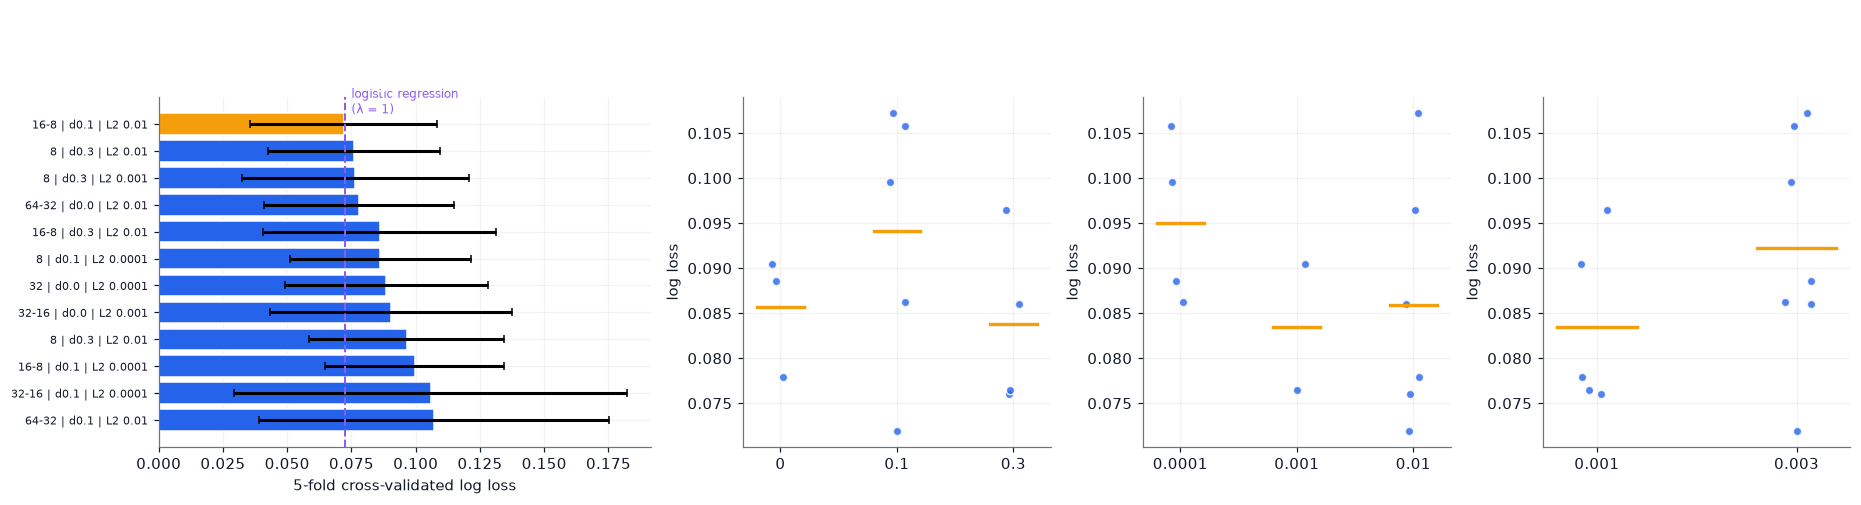

In [20]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.4), gridspec_kw={"width_ratios": [1.6, 1, 1, 1]})
ypos = np.arange(len(search))[::-1]
axes[0].barh(ypos, search["mean log loss"], xerr=search["SD over folds"], color=[COLORS["orange"] if i == 0 else COLORS["blue"] for i in range(len(search))], edgecolor="white", capsize=2.5)
axes[0].set_yticks(ypos); axes[0].set_yticklabels([f"{r.hidden_str} | d{r.dropout} | L2 {r.l2:g}" for r in search.itertuples()], fontsize=7.5)
axes[0].set_xlabel("5-fold cross-validated log loss"); axes[0].set_title("Random search (orange: selected)")
axes[0].axvline(loss_log.mean() if USE_LOG else loss_raw.mean(), color=COLORS["purple"], linestyle="--", linewidth=1.3); axes[0].annotate("logistic regression\n(\u03bb = 1)", (loss_log.mean() if USE_LOG else loss_raw.mean(), len(search) - 0.6), xytext=(4, 0), textcoords="offset points", fontsize=8, color=COLORS["purple"])
for ax, key, title in zip(axes[1:], ["dropout", "l2", "learning_rate"], ["Dropout", "L2 weight", "Learning rate"]):
    values = sorted(search[key].unique())
    for j, v in enumerate(values):
        sub = search[search[key] == v]["mean log loss"].to_numpy()
        ax.scatter(np.full(len(sub), j) + np.random.default_rng(j).uniform(-0.08, 0.08, len(sub)), sub, color=COLORS["blue"], alpha=0.8, s=30, edgecolor="white")
        ax.plot([j - 0.2, j + 0.2], [sub.mean()] * 2, color=COLORS["orange"], linewidth=2.2)
    ax.set_xticks(range(len(values))); ax.set_xticklabels([f"{v:g}" for v in values]); ax.set_title(title); ax.set_ylabel("log loss")
fig.suptitle("Hyperparameter search results (each dot is one configuration; orange line: mean of the group)", fontsize=12, fontweight="bold", x=0.01, ha="left", y=1.03)
finish(fig, "06_hyperparameter_search")

Read the right three panels as a **marginal view**: each dot is a configuration, and the orange bar is the mean of the group. Strong regularization (larger L2, some dropout) usually helps in this small-sample regime, but the **spread inside each group** is as large as the differences between groups: with 12 random draws we learn which *regions* are good, not a unique optimum. Compare the best neural configurations with the logistic-regression line (dashed): the neural network has to **beat it, not merely match it**, to justify its complexity.

## 13. Honest comparison by repeated cross-validation

We now compare all candidates on the **same folds**: 5-fold stratified cross-validation of the development set, repeated `N_REPEATS` times with different partitions. Inside every outer training set, *all* learning happens: preprocessing, the inner tuning of logistic regression and $k$-NN, and the training of the networks (the tuned configuration, `ENSEMBLE_SIZE` seeds). The **ensemble's first member** is also reported separately as the "single MLP". The out-of-fold predictions of the first repeat are kept for calibration (Section 14).

In [21]:
def run_cv_comparison(n_splits=5, n_repeats=N_REPEATS, seed=SEED):
    rows, oof = [], {m: np.zeros(len(y_dev)) for m in MODEL_COLORS}
    oof_member_std = np.zeros(len(y_dev))
    t0 = time.time()
    for rep in range(n_repeats):
        for f, (tr_i, te_i) in enumerate(stratified_kfold(y_dev, n_splits, seed + 100 * rep)):
            Xtr_raw, ytr, Xte_raw, yte = X_dev[tr_i], y_dev[tr_i], X_dev[te_i], y_dev[te_i]
            prep = Preprocessor(USE_LOG).fit(Xtr_raw); Xtr, Xte = prep.transform(Xtr_raw), prep.transform(Xte_raw)
            probs = {"Majority class": np.full(len(te_i), ytr.mean())}
            lam = inner_tune(logreg_predict, LAMBDA_GRID, Xtr_raw, ytr, USE_LOG, seed + f)
            probs["Logistic regression"] = logistic_proba(logistic_fit(Xtr, ytr, lam), Xte)
            k = inner_tune(knn_proba, K_GRID, Xtr_raw, ytr, USE_LOG, seed + f)
            probs["k-nearest neighbours"] = knn_proba(Xtr, ytr, Xte, k)
            members = [mlp_proba(fit_mlp(Xtr, ytr, best_config, seed=seed + 1000 * rep + 100 * f + m), Xte) for m in range(ENSEMBLE_SIZE)]
            probs["MLP (single)"] = members[0]
            probs["MLP ensemble"] = np.mean(members, axis=0)
            for name, p in probs.items():
                p = np.clip(p, 1e-7, 1 - 1e-7); pred = p >= P_STAR
                bm = binary_metrics(yte, pred)
                rows.append({"repeat": rep, "fold": f, "model": name, "log loss": log_loss(yte, p), "Brier": brier_score(yte, p),
                             "AUC": auc_rank(yte, p) if name != "Majority class" else 0.5, "cost at p*": expected_cost(yte, p, P_STAR),
                             "sensitivity at p*": bm["sensitivity"], "specificity at p*": bm["specificity"], "n_train": len(tr_i), "n_test": len(te_i)})
                if rep == 0:
                    oof[name][te_i] = p
            if rep == 0:
                oof_member_std[te_i] = np.std(members, axis=0)
        print(f"repeat {rep + 1}/{n_repeats} done ({time.time() - t0:.0f} s)")
    return pd.DataFrame(rows), oof, oof_member_std

cv_results, oof_probs, oof_std = run_cv_comparison()
summary_cv = cv_results.groupby("model").agg(**{m: (m, "mean") for m in ["log loss", "Brier", "AUC", "cost at p*", "sensitivity at p*", "specificity at p*"]}).reindex(list(MODEL_COLORS))
sd_cv = cv_results.groupby("model")[["log loss", "AUC", "cost at p*"]].std().reindex(list(MODEL_COLORS))
display(summary_cv.round(4))

repeat 1/3 done (543 s)
repeat 2/3 done (1078 s)
repeat 3/3 done (1575 s)


,log loss,Brier,AUC,cost at p*,sensitivity at p*,specificity at p*
model,,,,,,
Majority class,0.6604,0.2338,0.5000,0.6272,1.0000,0.0000
Logistic regression,0.0757,0.0194,0.9951,0.0892,0.9765,0.9277
k-nearest neighbours,0.1450,0.0363,0.9890,0.0899,0.9804,0.9149
MLP (single),0.0799,0.0199,0.9946,0.0724,0.9745,0.9603
MLP ensemble,0.0716,0.0180,0.9951,0.0790,0.9745,0.9498


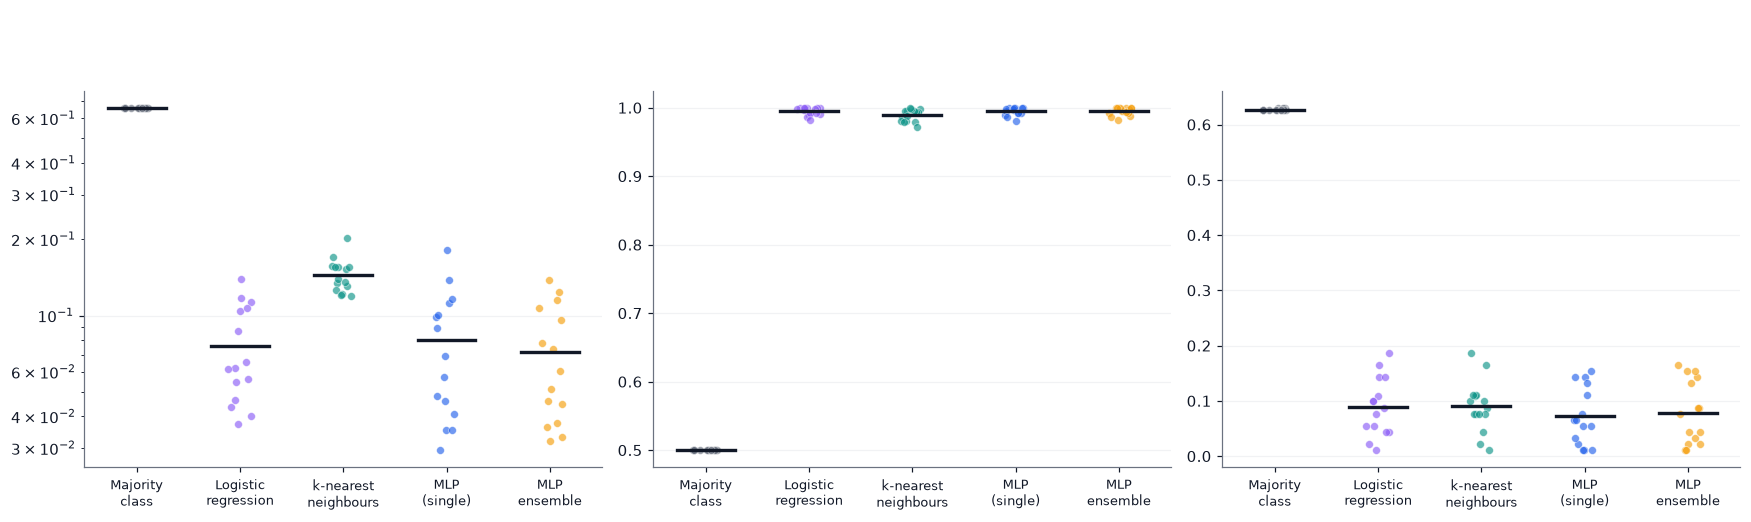

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
models_cv = list(MODEL_COLORS)
for ax, metric, label in zip(axes, ["log loss", "AUC", "cost at p*"], ["Log loss (lower is better)", "AUC (higher is better)", "Expected cost per patient at p* (lower is better)"]):
    for j, m in enumerate(models_cv):
        vals = cv_results[cv_results.model == m][metric].to_numpy()
        ax.scatter(np.full(len(vals), j) + np.random.default_rng(j).uniform(-0.12, 0.12, len(vals)), vals, color=MODEL_COLORS[m], alpha=0.65, s=26, edgecolor="white", linewidth=0.4)
        ax.plot([j - 0.28, j + 0.28], [vals.mean()] * 2, color=COLORS["dark"], linewidth=2.2)
    ax.set_xticks(range(len(models_cv))); ax.set_xticklabels([m.replace(" ", "\n", 1) for m in models_cv], fontsize=8.2); ax.set_title(label, fontsize=10.5); ax.grid(axis="x", visible=False)
axes[0].set_yscale("log")
fig.suptitle(f"Cross-validation results on the development set ({N_REPEATS} repeats of 5 folds; each dot is one fold, black line: mean)", fontsize=12, fontweight="bold", x=0.01, ha="left", y=1.02)
finish(fig, "07_cv_comparison")

In [23]:
# Paired comparisons against the logistic-regression baseline (the same folds): corrected resampled t-test.
rows = []
base = cv_results[cv_results.model == "Logistic regression"].reset_index(drop=True)
n_train_cv, n_test_cv = int(base["n_train"].iloc[0]), int(base["n_test"].iloc[0])
for m in ["k-nearest neighbours", "MLP (single)", "MLP ensemble"]:
    other = cv_results[cv_results.model == m].reset_index(drop=True)
    row = {"model": m}
    for metric in ["log loss", "AUC", "cost at p*"]:
        d = other[metric].to_numpy() - base[metric].to_numpy()
        t_stat, p_val = corrected_resampled_ttest(d, n_train_cv, n_test_cv)
        row[f"{metric}: difference vs LR (p)"] = f"{d.mean():+.4f} (p = {p_val:.2f})"
    rows.append(row)
display(pd.DataFrame(rows).set_index("model"))
print(f"Each of the {len(base)} folds has {n_train_cv} training and {n_test_cv} test samples; the corrected t-test accounts for the overlap between training sets.")
print("A negative difference in log loss or cost (a positive one in AUC) means that the model is better than logistic regression.")

,log loss: difference vs LR (p),AUC: difference vs LR (p),cost at p*: difference vs LR (p)
model,,,
k-nearest neighbours,+0.0694 (p = 0.00),-0.0061 (p = 0.08),+0.0007 (p = 0.97)
MLP (single),+0.0042 (p = 0.71),-0.0005 (p = 0.52),-0.0168 (p = 0.36)
MLP ensemble,-0.0041 (p = 0.40),-0.0000 (p = 0.96),-0.0102 (p = 0.43)


Each of the 15 folds has 364 training and 92 test samples; the corrected t-test accounts for the overlap between training sets.
A negative difference in log loss or cost (a positive one in AUC) means that the model is better than logistic regression.


How to read the comparison (compare with your own numbers):

- **Majority class** sets the floor (log loss $\approx H(\pi) = 0.66$, AUC 0.5). Every real model is far above it: the features are informative.
- **Logistic regression** is a very strong baseline on this dataset. The neural networks are often **close to it, not far above**, and the paired test tells whether any difference is distinguishable from fold-to-fold variation. A difference that is not significant should be reported as such — "the neural network matches logistic regression" is a valid scientific result.
- The **ensemble** typically improves on a single network (a smaller variance of the predictions, Section 11), especially for log loss, which penalizes unstable, overconfident predictions.
- **Cost at $p^{*}$** uses the *raw* probabilities; in Section 14 we calibrate them first, which may change the decision.

# Part E — Evaluation

## 14. Calibration and the decision threshold (development data only)

The out-of-fold (OOF) predictions of the first repeat give, for every development sample, a probability produced by a model that **never saw that sample**. We use them to study calibration and to fit the Platt correction (Section 8.3), without touching the test set.

To measure how much calibration helps *without* evaluating on the same data used to fit it, we use **cross-fitting**: split the OOF predictions into 5 folds, fit the Platt parameters on four of them, and apply them to the fifth.

In [24]:
def crossfit_platt(p, y_true, n_splits=5, seed=0):
    """Calibrated version of out-of-fold predictions p, each calibrated by parameters fitted on OTHER samples."""
    out = np.zeros_like(p)
    for tr_i, te_i in stratified_kfold(y_true, n_splits, seed):
        out[te_i] = platt_apply(p[te_i], platt_fit(p[tr_i], y_true[tr_i]))
    return out

calib_rows, cal_oof = [], {}
for m in ["Logistic regression", "MLP (single)", "MLP ensemble"]:
    raw = np.clip(oof_probs[m], 1e-7, 1 - 1e-7)
    cal = crossfit_platt(raw, y_dev); cal_oof[m] = cal
    for kind, p in [("raw", raw), ("Platt (cross-fitted)", cal)]:
        calib_rows.append({"model": m, "probabilities": kind, "log loss": log_loss(y_dev, p), "Brier": brier_score(y_dev, p),
                           "ECE (10 bins)": expected_calibration_error(y_dev, p), "AUC": auc_rank(y_dev, p), "cost at p*": expected_cost(y_dev, p, P_STAR)})
display(pd.DataFrame(calib_rows).set_index(["model", "probabilities"]).round(4))
a_b = platt_fit(oof_probs["MLP ensemble"], y_dev)
print(f"Platt parameters of the MLP ensemble (a, b) = ({a_b[0]:.3f}, {a_b[1]:.3f}):  a < 1 means the raw probabilities are overconfident; a > 1, underconfident")

log loss   Brier  ECE (10 bins)  \
model               probabilities                                           
Logistic regression raw                     0.0727  0.0187         0.0178   
                    Platt (cross-fitted)    0.0720  0.0177         0.0156   
MLP (single)        raw                     0.0741  0.0180         0.0158   
                    Platt (cross-fitted)    0.0757  0.0183         0.0146   
MLP ensemble        raw                     0.0709  0.0174         0.0152   
                    Platt (cross-fitted)    0.0717  0.0175         0.0147   

                                             AUC  cost at p*  
model               probabilities                             
Logistic regression raw                   0.9954      0.0921  
                    Platt (cross-fitted)  0.9947      0.0877  
MLP (single)        raw                   0.9932      0.0702  
                    Platt (cross-fitted)  0.9926      0.0724  
MLP ensemble        raw                   0.9941      0.0855  
                    Platt (cross-fitted)  0.9933      0.0921

Platt parameters of the MLP ensemble (a, b) = (1.123, 0.280):  a < 1 means the raw probabilities are overconfident; a > 1, underconfident


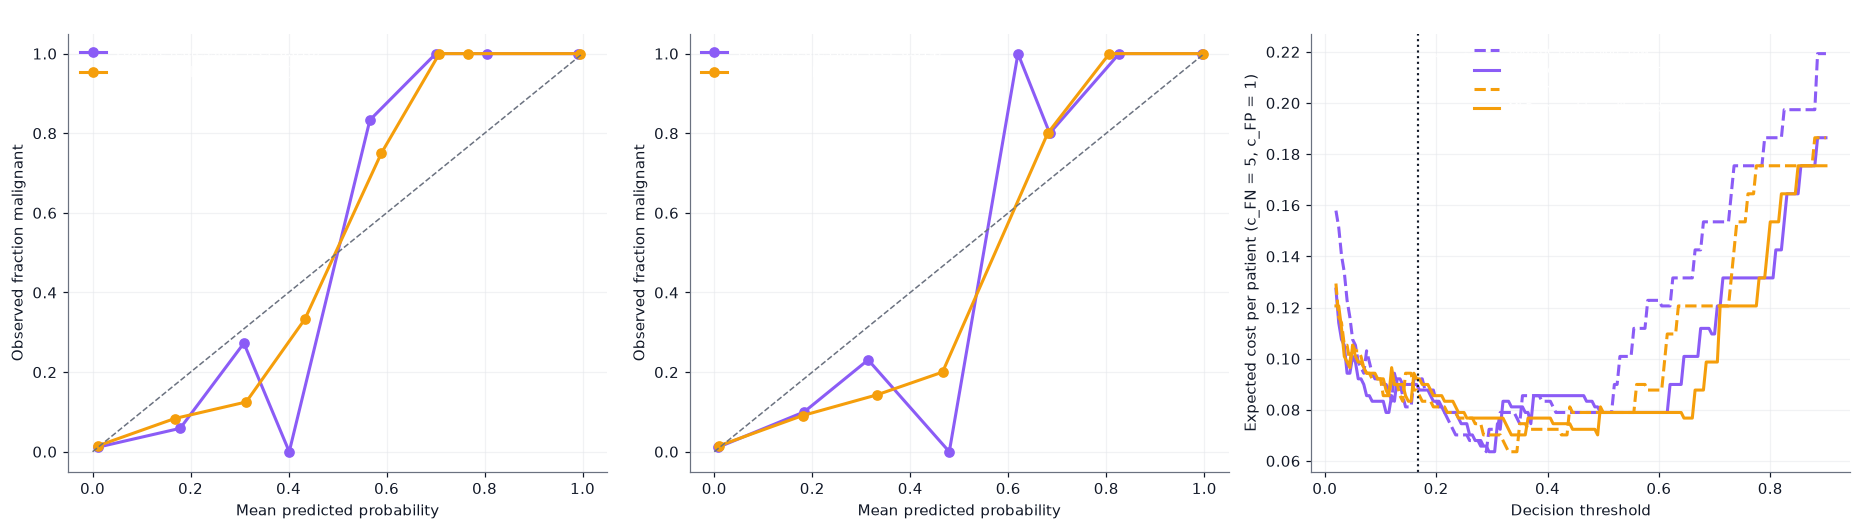

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.9))
for ax, source, title in [(axes[0], {m: np.clip(oof_probs[m], 1e-7, 1 - 1e-7) for m in ["Logistic regression", "MLP ensemble"]}, "Raw out-of-fold probabilities"),
                          (axes[1], {m: cal_oof[m] for m in ["Logistic regression", "MLP ensemble"]}, "After Platt scaling (cross-fitted)")]:
    for m, p in source.items():
        rel = reliability_bins(y_dev, p, 8)
        ax.plot(rel[:, 0], rel[:, 1], "o-", color=MODEL_COLORS[m], label=f"{m}  (ECE {expected_calibration_error(y_dev, p, 8):.3f})")
    ax.plot([0, 1], [0, 1], color=COLORS["gray"], linestyle="--", linewidth=1)
    ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Observed fraction malignant"); ax.set_title(title); ax.legend(loc="upper left", fontsize=8.5)
ts = np.linspace(0.02, 0.9, 177)
for m, color in [("Logistic regression", MODEL_COLORS["Logistic regression"]), ("MLP ensemble", MODEL_COLORS["MLP ensemble"])]:
    axes[2].plot(ts, [expected_cost(y_dev, np.clip(oof_probs[m], 1e-7, 1 - 1e-7), t) for t in ts], color=color, linestyle="--", label=f"{m}, raw")
    axes[2].plot(ts, [expected_cost(y_dev, cal_oof[m], t) for t in ts], color=color, label=f"{m}, calibrated")
axes[2].axvline(P_STAR, color=COLORS["dark"], linestyle=":", linewidth=1.4); axes[2].annotate(f"p* = {P_STAR:.3f}", (P_STAR, axes[2].get_ylim()[1] * 0.95), xytext=(5, 0), textcoords="offset points", fontsize=9)
axes[2].set_xlabel("Decision threshold"); axes[2].set_ylabel(f"Expected cost per patient (c_FN = {COST_FN:g}, c_FP = {COST_FP:g})"); axes[2].set_title("Cost as a function of the threshold"); axes[2].legend(fontsize=8)
finish(fig, "08_calibration_and_cost")

The reliability diagrams show whether the probabilities can be read as risks; the right panel shows the **cost curve**: for calibrated probabilities the minimum should lie near the theoretical $p^{*} = 1/6$ (Section 8.4), while for a miscalibrated model the best threshold is displaced. With only 455 samples and 8 bins the curves are noisy; the cross-fitted metrics in the table are the more reliable comparison. The threshold is **fixed at $p^{*}$ from the costs** (declared in Section 2), not tuned on these curves.

## 15. Final model and the one-time test evaluation

Everything has been decided on the development set. We now **train the final models on all 455 development samples** with the chosen settings (preprocessing refitted on all development data, logistic regression with the penalty chosen by inner cross-validation, $k$-NN with the chosen $k$, the MLP ensemble with the selected configuration), apply the Platt parameters fitted on the OOF predictions, and evaluate **once** on the locked test set of 114 samples.

In [26]:
prep_final = Preprocessor(USE_LOG).fit(X_dev)
Xd_final, Xt_final = prep_final.transform(X_dev), prep_final.transform(X_test)

w_lr = logistic_fit(Xd_final, y_dev, lam_dev)
final_models = [fit_mlp(Xd_final, y_dev, best_config, seed=SEED + 5000 + m) for m in range(ENSEMBLE_SIZE)]
def ensemble_predict(models, X):
    return np.mean([mlp_proba(m, X) for m in models], axis=0)
def ensemble_members(models, X):
    return np.stack([mlp_proba(m, X) for m in models])

member_test = ensemble_members(final_models, Xt_final)
test_raw = {"Majority class": np.full(len(y_test), y_dev.mean()), "Logistic regression": np.clip(logistic_proba(w_lr, Xt_final), 1e-7, 1 - 1e-7),
            "k-nearest neighbours": knn_proba(Xd_final, y_dev, Xt_final, k_dev), "MLP (single)": member_test[0], "MLP ensemble": member_test.mean(axis=0)}
platt_params = {m: platt_fit(oof_probs[m], y_dev) for m in ["Logistic regression", "MLP ensemble"]}
test_prob = dict(test_raw)
for m, params in platt_params.items():
    test_prob[m] = platt_apply(test_raw[m], params)                       # calibrated versions of the two main models
print("Final models trained on", len(y_dev), "development samples. Test samples:", len(y_test), "| malignant:", int(y_test.sum()))
print("Platt parameters:", {m: tuple(round(v, 3) for v in p) for m, p in platt_params.items()})

Final models trained on 456 development samples. Test samples: 113 | malignant: 42
Platt parameters: {'Logistic regression': (1.327, 0.359), 'MLP ensemble': (1.123, 0.28)}


In [27]:
rows = []
for m in MODEL_COLORS:
    p = test_prob[m]; pred = p >= P_STAR; bm = binary_metrics(y_test, pred)
    s_lo, s_hi = wilson_interval(bm["TP"], bm["TP"] + bm["FN"]); sp_lo, sp_hi = wilson_interval(bm["TN"], bm["TN"] + bm["FP"])
    if m == "Majority class":
        auc_txt = "0.500"
    else:
        lo, hi = bootstrap_ci(auc_rank, y_test, p)
        auc_txt = f"{auc_rank(y_test, p):.3f} [{lo:.3f}, {hi:.3f}]"
    rows.append({"model": m + (" (Platt)" if m in platt_params else ""), "log loss": round(log_loss(y_test, p), 4), "Brier": round(brier_score(y_test, p), 4), "AUC [95% CI]": auc_txt,
                 "sensitivity at p*": f"{bm['sensitivity']:.3f} [{s_lo:.3f}, {s_hi:.3f}]" if not np.isnan(bm["sensitivity"]) else "n/a",
                 "specificity at p*": f"{bm['specificity']:.3f} [{sp_lo:.3f}, {sp_hi:.3f}]", "FN / FP": f"{bm['FN']} / {bm['FP']}", "cost at p*": round(expected_cost(y_test, p, P_STAR), 3)})
test_table = pd.DataFrame(rows).set_index("model")
display(test_table)
print(f"Test set: {len(y_test)} samples ({int(y_test.sum())} malignant). Sensitivity intervals are based on only {int(y_test.sum())} malignant samples (Wilson intervals).")

# Paired comparison of the two main models: same samples, decisions at p*.
corr_ens = (test_prob["MLP ensemble"] >= P_STAR) == y_test.astype(bool)
corr_lr = (test_prob["Logistic regression"] >= P_STAR) == y_test.astype(bool)
b, c, p_mc = mcnemar_exact(corr_ens, corr_lr)
r = np.random.default_rng(5); d_auc = []
for _ in range(N_BOOT):
    idx = r.integers(0, len(y_test), size=len(y_test))
    if y_test[idx].min() == y_test[idx].max():
        continue
    d_auc.append(auc_rank(y_test[idx], test_prob["MLP ensemble"][idx]) - auc_rank(y_test[idx], test_prob["Logistic regression"][idx]))
lo, hi = np.percentile(d_auc, [2.5, 97.5])
print(f"\nMLP ensemble vs logistic regression on the test set: AUC difference {auc_rank(y_test, test_prob['MLP ensemble']) - auc_rank(y_test, test_prob['Logistic regression']):+.3f}, paired bootstrap 95% interval [{lo:+.3f}, {hi:+.3f}]")
print(f"McNemar exact test of the decisions at p*: only ensemble right = {b}, only logistic regression right = {c}, p = {p_mc:.3g}")

,log loss,Brier,AUC [95% CI],sensitivity at p*,specificity at p*,FN / FP,cost at p*
model,,,,,,,
Majority class,0.6598,0.2335,0.500,"1.000 [0.916, 1.000]","0.000 [0.000, 0.051]",0 / 71,0.628
Logistic regression (Platt),0.0750,0.0229,"0.997 [0.991, 1.000]","0.976 [0.877, 0.996]","0.930 [0.846, 0.970]",1 / 5,0.088
k-nearest neighbours,0.1492,0.0376,"0.995 [0.985, 1.000]","0.976 [0.877, 0.996]","0.901 [0.810, 0.951]",1 / 7,0.106
MLP (single),0.0808,0.0254,"0.997 [0.990, 1.000]","0.976 [0.877, 0.996]","0.944 [0.864, 0.978]",1 / 4,0.080
MLP ensemble (Platt),0.0805,0.0242,"0.996 [0.987, 1.000]","0.976 [0.877, 0.996]","0.944 [0.864, 0.978]",1 / 4,0.080


Test set: 113 samples (42 malignant). Sensitivity intervals are based on only 42 malignant samples (Wilson intervals).

MLP ensemble vs logistic regression on the test set: AUC difference -0.001, paired bootstrap 95% interval [-0.005, +0.000]
McNemar exact test of the decisions at p*: only ensemble right = 1, only logistic regression right = 0, p = 1


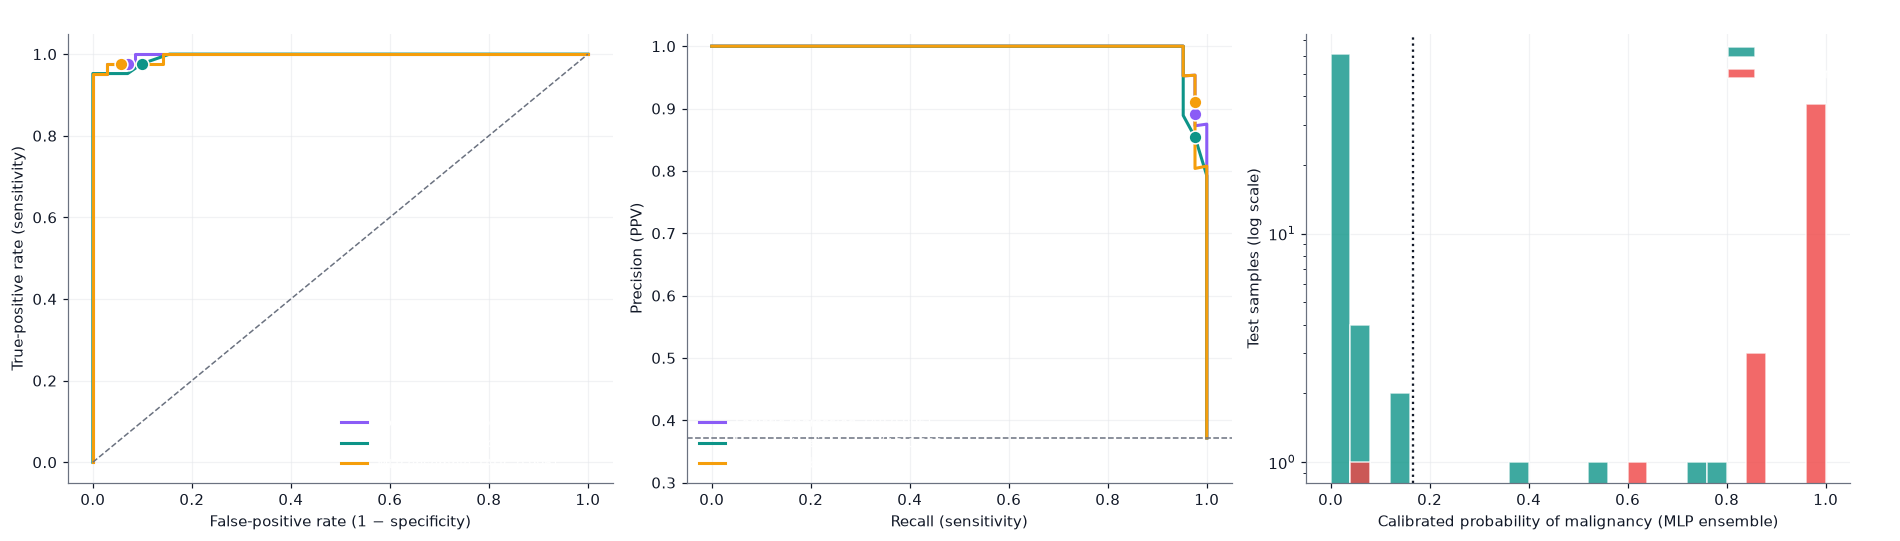

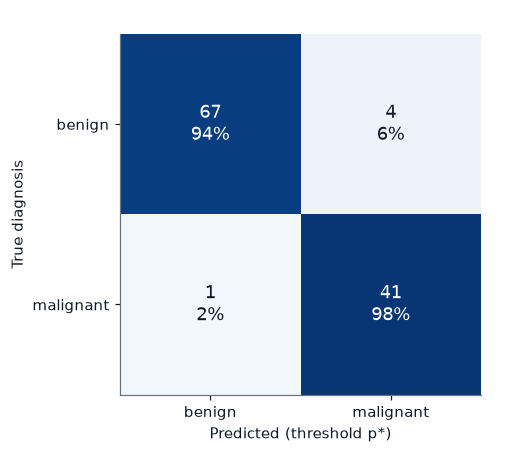

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.0))
for m in ["Logistic regression", "k-nearest neighbours", "MLP ensemble"]:
    p = test_prob[m]
    fpr, tpr = roc_curve_np(y_test, p); prec, rec = pr_curve_np(y_test, p)
    axes[0].plot(fpr, tpr, color=MODEL_COLORS[m], label=f"{m}  (AUC {auc_rank(y_test, p):.3f})")
    axes[1].plot(rec, prec, color=MODEL_COLORS[m], label=f"{m}  (AP {average_precision(y_test, p):.3f})")
    bm = binary_metrics(y_test, p >= P_STAR)
    axes[0].scatter([1 - bm["specificity"]], [bm["sensitivity"]], color=MODEL_COLORS[m], s=70, edgecolor="white", zorder=5)
    axes[1].scatter([bm["sensitivity"]], [bm["PPV"]], color=MODEL_COLORS[m], s=70, edgecolor="white", zorder=5)
axes[0].plot([0, 1], [0, 1], color=COLORS["gray"], linestyle="--", linewidth=1); axes[0].set_xlabel("False-positive rate (1 \u2212 specificity)"); axes[0].set_ylabel("True-positive rate (sensitivity)")
axes[0].set_title("ROC curves on the test set (dots: operating point at p*)"); axes[0].legend(loc="lower right", fontsize=8.5)
axes[1].axhline(y_test.mean(), color=COLORS["gray"], linestyle="--", linewidth=1); axes[1].set_xlabel("Recall (sensitivity)"); axes[1].set_ylabel("Precision (PPV)"); axes[1].set_ylim(0.3, 1.02)
axes[1].set_title("Precision\u2013recall curves (dashed: chance = prevalence)"); axes[1].legend(loc="lower left", fontsize=8.5)

pe = test_prob["MLP ensemble"]
bins = np.linspace(0, 1, 26)
axes[2].hist(pe[y_test == 0], bins=bins, color=CLASS_COLORS["benign"], alpha=0.8, edgecolor="white", label="benign")
axes[2].hist(pe[y_test == 1], bins=bins, color=CLASS_COLORS["malignant"], alpha=0.8, edgecolor="white", label="malignant")
axes[2].axvline(P_STAR, color=COLORS["dark"], linestyle=":", linewidth=1.5); axes[2].set_yscale("log")
axes[2].set_xlabel("Calibrated probability of malignancy (MLP ensemble)"); axes[2].set_ylabel("Test samples (log scale)"); axes[2].set_title("The model separates the classes; p* is a conservative cut"); axes[2].legend()
finish(fig, "09_test_roc_pr_hist")

bm = binary_metrics(y_test, test_prob["MLP ensemble"] >= P_STAR)
cm = np.array([[bm["TN"], bm["FP"]], [bm["FN"], bm["TP"]]])
fig, ax = plt.subplots(figsize=(4.8, 4.2))
ax.imshow(cm / cm.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=1); ax.grid(False)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]}\n{100 * cm[i, j] / cm[i].sum():.0f}%", ha="center", va="center", fontsize=12, color="white" if cm[i, j] / cm[i].sum() > 0.55 else COLORS["dark"])
ax.set_xticks([0, 1]); ax.set_xticklabels(["benign", "malignant"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["benign", "malignant"])
ax.set_xlabel("Predicted (threshold p*)"); ax.set_ylabel("True diagnosis"); ax.set_title("Test confusion matrix, MLP ensemble")
finish(fig, "10_test_confusion")

Interpretation guide: report the **intervals**, not just the point values. With ~42 malignant test samples, a sensitivity of $41/42$ has a Wilson interval that reaches well below 90% (Notebook 07); and the AUC of several models will have heavily overlapping bootstrap intervals. The paired comparison with logistic regression is the correct way to test whether the neural network adds anything: on a dataset where the classes are almost linearly separable, a difference that is within the interval of zero means that **the simpler model is just as good** — and then simplicity, transparency, and calibration are the arguments for choosing between them.

## 16. Clinical usefulness: calibration on the test set and decision curves

Accuracy and AUC do not say whether *using* the model leads to better decisions. The **decision curve** (Section 8.4) plots the net benefit against the threshold probability $t$ for: the model, "treat all", and "treat none". A model is useful at thresholds where its curve lies **above both** references. The vertical line marks $p^{*}$, the threshold implied by our cost assumption.

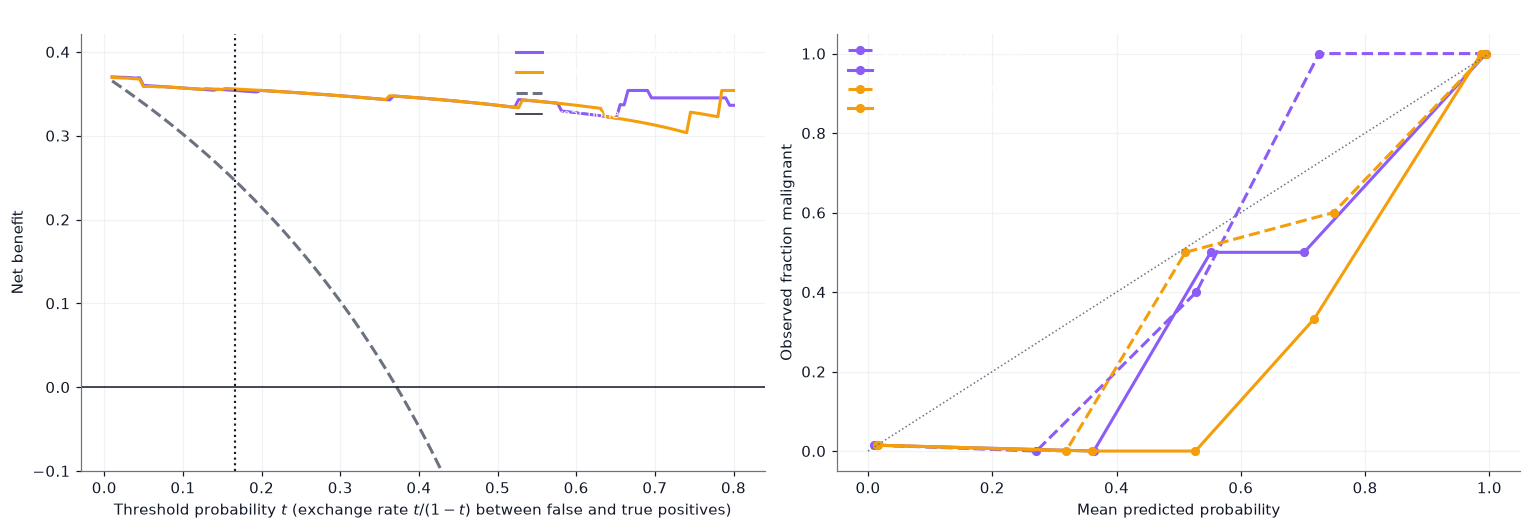

Net benefit at t = p* = 0.167: {'Logistic regression': np.float64(0.354), 'MLP ensemble': np.float64(0.3558)} | treat all: 0.246 | treat none: 0


In [29]:
ts = np.linspace(0.01, 0.80, 160)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.9))
for m in ["Logistic regression", "MLP ensemble"]:
    axes[0].plot(ts, [net_benefit(y_test, test_prob[m], t) for t in ts], color=MODEL_COLORS[m], label=m + " (calibrated)")
treat_all = [y_test.mean() - (1 - y_test.mean()) * t / (1 - t) for t in ts]
axes[0].plot(ts, treat_all, color=COLORS["gray"], linestyle="--", label="treat all"); axes[0].axhline(0, color=COLORS["dark"], linewidth=1, label="treat none")
axes[0].axvline(P_STAR, color=COLORS["dark"], linestyle=":", linewidth=1.4); axes[0].annotate(f"p* = {P_STAR:.3f}", (P_STAR, 0.33), xytext=(5, 0), textcoords="offset points", fontsize=9)
axes[0].set_ylim(-0.1, y_test.mean() + 0.05); axes[0].set_xlabel("Threshold probability $t$ (exchange rate $t/(1-t)$ between false and true positives)"); axes[0].set_ylabel("Net benefit")
axes[0].set_title("Decision curve analysis (test set)"); axes[0].legend(loc="upper right", fontsize=8.5)

for m in ["Logistic regression", "MLP ensemble"]:
    for kind, p, ls in [("raw", test_raw[m], "--"), ("Platt", test_prob[m], "-")]:
        rel = reliability_bins(y_test, p, 5)
        axes[1].plot(rel[:, 0], rel[:, 1], "o" + ls, color=MODEL_COLORS[m], label=f"{m}, {kind}", markersize=5)
axes[1].plot([0, 1], [0, 1], color=COLORS["gray"], linestyle=":", linewidth=1)
axes[1].set_xlabel("Mean predicted probability"); axes[1].set_ylabel("Observed fraction malignant"); axes[1].set_title("Reliability on the test set (5 bins; few samples per bin)"); axes[1].legend(fontsize=8)
finish(fig, "11_decision_curve_and_calibration")
nb_star = {m: net_benefit(y_test, test_prob[m], P_STAR) for m in ["Logistic regression", "MLP ensemble"]}
print(f"Net benefit at t = p* = {P_STAR:.3f}:", {m: round(v, 4) for m, v in nb_star.items()}, "| treat all:", round(y_test.mean() - (1 - y_test.mean()) * P_STAR / (1 - P_STAR), 4), "| treat none: 0")

## 17. Uncertainty: when should the model say "ask an expert"?

An ensemble provides, besides the average probability, a measure of **epistemic uncertainty**: the disagreement of its members (the standard deviation of the member probabilities). If the model is useful as a **decision-support tool**, the samples on which it is *uncertain* should be the ones that are referred to a human. We check whether the member disagreement is related to errors, and draw the **selective-prediction curve**: the error rate among the retained samples as a function of the fraction of samples referred to an expert (the most uncertain first).

Errors at p* on the test set (MLP ensemble): 5 of 113


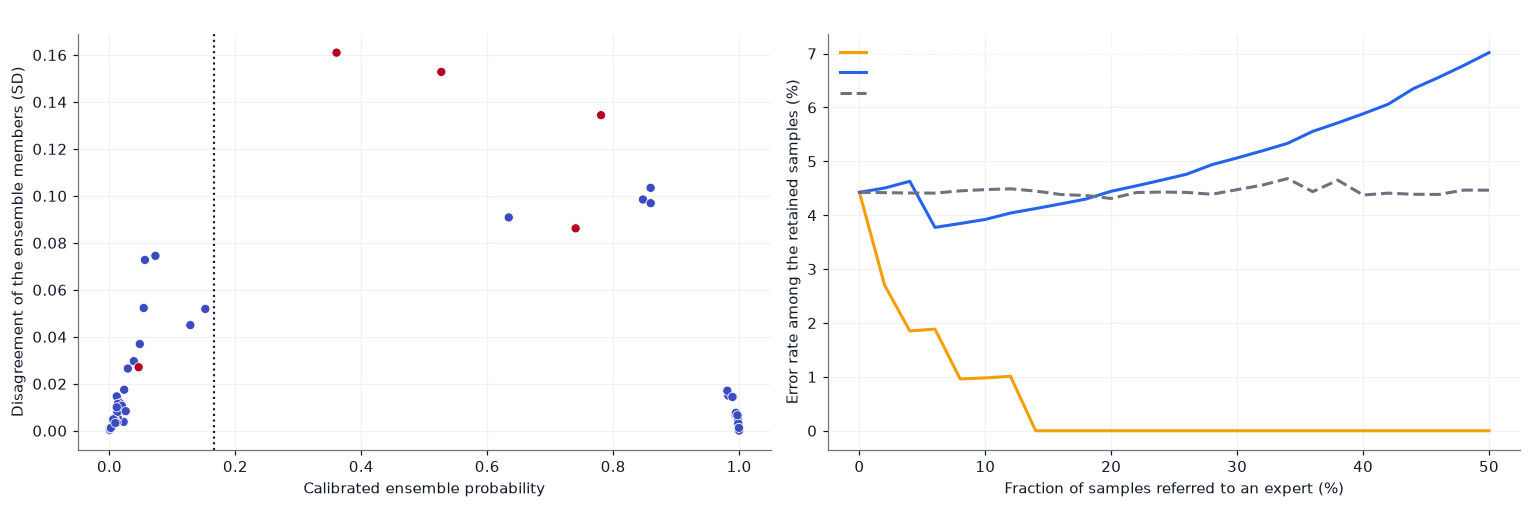

Mean disagreement: correct predictions 0.0103 | errors 0.1123


In [30]:
member_std = member_test.std(axis=0)
p_ens = test_prob["MLP ensemble"]; pred_ens = p_ens >= P_STAR
error = pred_ens != y_test.astype(bool)
print(f"Errors at p* on the test set (MLP ensemble): {int(error.sum())} of {len(y_test)}")

order = np.argsort(-member_std)                         # most uncertain first
fractions = np.linspace(0, 0.5, 26)
err_rate_by_std = [error[order[int(round(f * len(order))):]].mean() if int(round(f * len(order))) < len(order) else 0 for f in fractions]
margin = np.abs(p_ens - P_STAR); order_margin = np.argsort(margin)                   # closest to the decision threshold first
err_rate_by_margin = [error[order_margin[int(round(f * len(order))):]].mean() for f in fractions]
rng_ref = np.random.default_rng(0)
random_curve = np.mean([[error[rng_ref.permutation(len(order))[int(round(f * len(order))):]].mean() for f in fractions] for _ in range(200)], axis=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.7))
sc = axes[0].scatter(p_ens, member_std, c=np.where(error, 1, 0), cmap="coolwarm", s=36, edgecolor="white", linewidth=0.5, vmin=0, vmax=1)
axes[0].axvline(P_STAR, color=COLORS["dark"], linestyle=":", linewidth=1.4)
axes[0].set_xlabel("Calibrated ensemble probability"); axes[0].set_ylabel("Disagreement of the ensemble members (SD)")
axes[0].set_title("Uncertainty on the test set (red: misclassified at p*)")
axes[1].plot(fractions * 100, np.array(err_rate_by_std) * 100, color=COLORS["orange"], label="refer the most uncertain (member disagreement)")
axes[1].plot(fractions * 100, np.array(err_rate_by_margin) * 100, color=COLORS["blue"], label="refer the samples closest to the threshold")
axes[1].plot(fractions * 100, random_curve * 100, color=COLORS["gray"], linestyle="--", label="refer at random")
axes[1].set_xlabel("Fraction of samples referred to an expert (%)"); axes[1].set_ylabel("Error rate among the retained samples (%)"); axes[1].set_title("Selective prediction"); axes[1].legend(fontsize=8.5)
finish(fig, "12_uncertainty")
print(f"Mean disagreement: correct predictions {member_std[~error].mean():.4f} | errors {member_std[error].mean() if error.any() else float('nan'):.4f}")

With a very small number of errors on 114 test samples, these curves are **anecdotal**: read them as an illustration of the method (and of how to ask the question), not as an estimate. On a larger data set the same analysis quantifies how much a **referral policy** (the 10% most uncertain cases go to an expert) would reduce the error rate. Note also that member disagreement captures *model* uncertainty, not *data* ambiguity or distribution shift: a sample very different from all training samples could still be classified confidently by all members.

# Part F — Interpretation and delivery

## 18. What does the model use? Permutation importance and coefficients

**Permutation importance** (Breiman, 2001): shuffle the values of one feature across the test samples — breaking its relationship with the label while keeping its marginal distribution — and measure how much the performance **drops**. A large drop means the model relies on that feature. For feature set $S$ and a metric $M$ (higher is better, e.g. AUC),

$$
\text{Importance}(S) = M(\text{original data}) - \mathbb{E}_{\pi}\big[M(\text{data with the columns in } S \text{ permuted by } \pi)\big] .
$$

Two warnings that matter on this dataset:

1. **Correlated features share importance.** If radius, perimeter, and area are nearly interchangeable, permuting *one* of them barely hurts (the model uses the others), so the importance of each is underestimated. The remedy is **grouped** permutation: permute a *group* of related features together (all three statistics of one measurement, or all features of one statistic).
2. **Importance is a property of the model and the data, not of the biology.** It says what *this model* uses, not what *causes* malignancy.

We compute the importance of each of the 30 features, and of the 10 measurement groups and 3 statistic groups, on the **test set**, for the ensemble (the test set is no longer used for any decision). For comparison we also show the **standardized coefficients** of the logistic regression, with bootstrap intervals from refitting on resampled development data — which expose the instability caused by collinearity.

In [31]:
def permutation_importance(models, Xs, y_true, groups, n_rep=N_PERM, seed=0):
    """Drop in AUC and increase in log loss when the columns of each group are permuted jointly (n_rep repetitions)."""
    r = np.random.default_rng(seed); n, d = Xs.shape
    base_p = ensemble_predict(models, Xs); base_auc, base_ll = auc_rank(y_true, base_p), log_loss(y_true, base_p)
    out = {}
    for name, cols in groups.items():
        stack = np.repeat(Xs[None], n_rep, axis=0)                                    # (n_rep, n, d)
        for k in range(n_rep):
            stack[k][:, cols] = Xs[r.permutation(n)][:, cols]                          # the same permutation for all columns of the group
        p = ensemble_predict(models, stack.reshape(n_rep * n, d)).reshape(n_rep, n)
        auc_drop = base_auc - np.array([auc_rank(y_true, p[k]) for k in range(n_rep)])
        ll_inc = np.array([log_loss(y_true, p[k]) for k in range(n_rep)]) - base_ll
        out[name] = (auc_drop.mean(), auc_drop.std(), ll_inc.mean(), ll_inc.std())
    return pd.DataFrame(out, index=["AUC drop", "AUC drop SD", "log-loss increase", "log-loss increase SD"]).T

single_groups = {n: [i] for i, n in enumerate(FEATURE_NAMES)}
measure_groups = {m: [FEATURE_NAMES.index(f"{m}_{s}") for s in STATISTICS] for m in MEASUREMENTS}
statistic_groups = {s: [FEATURE_NAMES.index(f"{m}_{s}") for m in MEASUREMENTS] for s in STATISTICS}
t0 = time.time()
imp_single = permutation_importance(final_models, Xt_final, y_test, single_groups)
imp_measure = permutation_importance(final_models, Xt_final, y_test, measure_groups)
imp_stat = permutation_importance(final_models, Xt_final, y_test, statistic_groups)
print(f"Done in {time.time() - t0:.0f} s")
print("Sum of the single-feature log-loss increases:", round(float(imp_single["log-loss increase"].sum()), 4), "| log-loss increase when ALL features of a group are permuted together (largest group):",
      round(float(imp_measure["log-loss increase"].max()), 4), "(grouped importance can be larger than the sum of its parts, because of redundancy)")

Done in 55 s
Sum of the single-feature log-loss increases: 0.2694 | log-loss increase when ALL features of a group are permuted together (largest group): 0.0974 (grouped importance can be larger than the sum of its parts, because of redundancy)


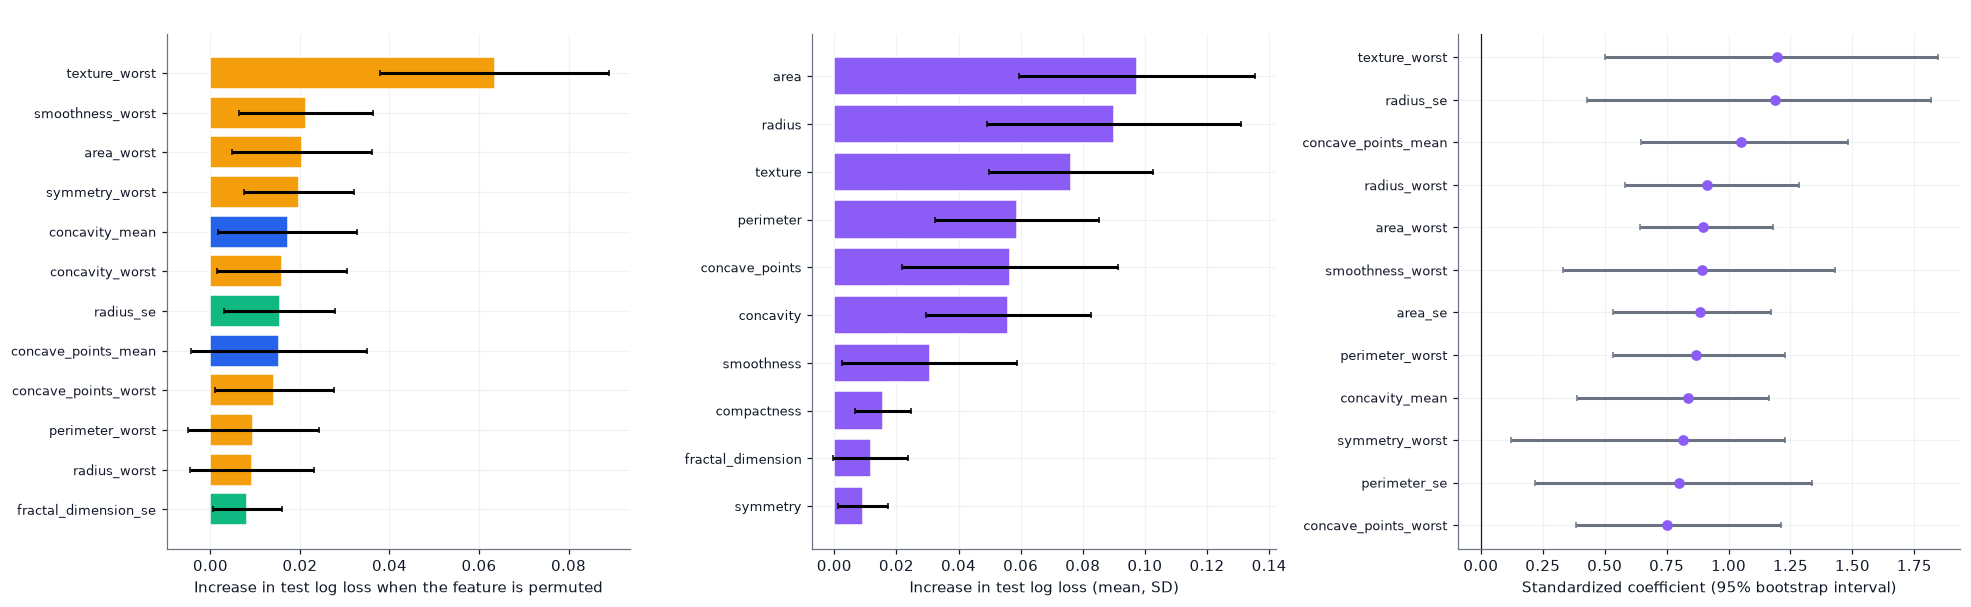

Share of the 30 coefficient intervals that include 0: 0.37 (many 'important' features have intervals that cross zero: collinearity)
Grouped importance, by statistic (log-loss increase): {'mean': 0.2278, 'se': 0.0709, 'worst': 1.0403}


In [32]:
# Standardized logistic-regression coefficients with bootstrap intervals (refitting on resampled development data).
rb = np.random.default_rng(11); coef_boot = []
for _ in range(100 if QUICK_MODE else 300):
    idx = rb.integers(0, len(y_dev), size=len(y_dev))
    if y_dev[idx].min() == y_dev[idx].max():
        continue
    pb = Preprocessor(USE_LOG).fit(X_dev[idx])
    coef_boot.append(logistic_fit(pb.transform(X_dev[idx]), y_dev[idx], lam_dev)[1:])
coef_boot = np.array(coef_boot); coef_hat = w_lr[1:]
coef_lo, coef_hi = np.percentile(coef_boot, [2.5, 97.5], axis=0)

top = imp_single["log-loss increase"].sort_values(ascending=False).head(12).index.tolist()
fig, axes = plt.subplots(1, 3, figsize=(18, 5.6), gridspec_kw={"width_ratios": [1.2, 1.2, 1.3]})
y_ = np.arange(len(top))[::-1]
axes[0].barh(y_, imp_single.loc[top, "log-loss increase"], xerr=imp_single.loc[top, "log-loss increase SD"], color=[GROUP_COLORS[n.split("_")[-1]] for n in top], edgecolor="white", capsize=2)
axes[0].set_yticks(y_); axes[0].set_yticklabels(top, fontsize=8.5); axes[0].set_xlabel("Increase in test log loss when the feature is permuted"); axes[0].set_title("Single-feature permutation importance")
grp = imp_measure["log-loss increase"].sort_values()
axes[1].barh(range(len(grp)), grp.values, xerr=imp_measure.loc[grp.index, "log-loss increase SD"], color=COLORS["purple"], edgecolor="white", capsize=2)
axes[1].set_yticks(range(len(grp))); axes[1].set_yticklabels(grp.index, fontsize=8.5); axes[1].set_xlabel("Increase in test log loss (mean, SD)"); axes[1].set_title("Grouped importance: all three statistics of a measurement")
order_c = np.argsort(np.abs(coef_hat))[::-1][:12]; yc = np.arange(len(order_c))[::-1]
axes[2].errorbar(coef_hat[order_c], yc, xerr=[coef_hat[order_c] - coef_lo[order_c], coef_hi[order_c] - coef_hat[order_c]], fmt="o", color=COLORS["purple"], ecolor=COLORS["gray"], capsize=2)
axes[2].axvline(0, color=COLORS["dark"], linewidth=0.8); axes[2].set_yticks(yc); axes[2].set_yticklabels([FEATURE_NAMES[i] for i in order_c], fontsize=8.5)
axes[2].set_xlabel("Standardized coefficient (95% bootstrap interval)"); axes[2].set_title("Logistic regression: coefficients are unstable")
finish(fig, "13_importance")
print("Share of the 30 coefficient intervals that include 0:", f"{np.mean((coef_lo < 0) & (coef_hi > 0)):.2f}", "(many 'important' features have intervals that cross zero: collinearity)")
print("Grouped importance, by statistic (log-loss increase):", {s: round(float(imp_stat.loc[s, 'log-loss increase']), 4) for s in STATISTICS})

What to look for: (1) the **worst** and **mean** values of size and contour-irregularity measurements (radius, perimeter, area, concavity, concave points) dominate, in line with the univariate analysis of Section 6.2 and with what pathologists look at; (2) the **single-feature importance is small for each of the redundant features**, while the **grouped** importance is much larger — a direct demonstration of the redundancy warning; (3) the coefficients of the logistic regression have **wide intervals that often cross zero**, even though the model predicts well: *prediction is stable, attribution is not*. Statements such as "feature X is the most important marker of malignancy" are therefore not supported by this analysis; at most, "the model relies on measurements of nuclear size and contour irregularity".

## 19. Error analysis

We look at the individual test samples that the final ensemble gets wrong at $p^{*}$, and at the samples with the least confident correct decisions.

In [33]:
pe_cal, pe_raw = test_prob["MLP ensemble"], test_raw["MLP ensemble"]
tab = pd.DataFrame({"ID": ids_test, "diagnosis": np.where(y_test == 1, "malignant", "benign"), "p (calibrated)": pe_cal.round(3), "member SD": member_std.round(3),
                    "decision at p*": np.where(pe_cal >= P_STAR, "malignant", "benign"), "radius_worst": X_test[:, FEATURE_NAMES.index("radius_worst")].round(1),
                    "concave_points_worst": X_test[:, FEATURE_NAMES.index("concave_points_worst")].round(3), "LR p": test_prob["Logistic regression"].round(3)})
tab["error"] = tab["diagnosis"] != tab["decision at p*"]
print(f"Misclassified at p*: {int(tab['error'].sum())} of {len(tab)} -> false negatives (the costly error): {int(((tab['diagnosis'] == 'malignant') & (tab['decision at p*'] == 'benign')).sum())}, false positives: {int(((tab['diagnosis'] == 'benign') & (tab['decision at p*'] == 'malignant')).sum())}")
display(tab[tab["error"]].reset_index(drop=True))
print("\nThe 6 test samples closest to the threshold (whether or not they are errors):")
display(tab.assign(distance=np.abs(tab["p (calibrated)"] - P_STAR)).sort_values("distance").head(6).drop(columns=["error", "distance"]).reset_index(drop=True))

Misclassified at p*: 5 of 113 -> false negatives (the costly error): 1, false positives: 4


,ID,diagnosis,p (calibrated),member SD,decision at p*,radius_worst,concave_points_worst,LR p,error
0,91813701,benign,0.527,0.153,malignant,15.4,0.143,0.363,True
1,9010872,benign,0.740,0.086,malignant,18.1,0.091,0.663,True
2,855167,malignant,0.046,0.027,benign,15.9,0.111,0.045,True
3,921386,benign,0.781,0.134,malignant,16.2,0.120,0.655,True
4,9112085,benign,0.361,0.161,malignant,15.0,0.078,0.525,True



The 6 test samples closest to the threshold (whether or not they are errors):


,ID,diagnosis,p (calibrated),member SD,decision at p*,radius_worst,concave_points_worst,LR p
0,89813,benign,0.152,0.052,benign,16.7,0.141,0.196
1,866458,benign,0.128,0.045,benign,16.1,0.142,0.139
2,91858,benign,0.073,0.074,benign,13.5,0.101,0.024
3,868223,benign,0.056,0.073,benign,13.3,0.070,0.001
4,8911164,benign,0.054,0.052,benign,12.4,0.089,0.023
5,9113816,benign,0.048,0.037,benign,13.6,0.055,0.027


Errors near the decision boundary are expected: a few samples have nuclear features typical of the other class (a benign mass with irregular nuclei, a small malignant one with regular nuclei). The question to ask for each error is whether a **pathologist would also hesitate** and whether the model's **probability and member disagreement flagged the uncertainty** (Section 17). A *confidently wrong* prediction with no disagreement would deserve a closer look at the sample (a possible labelling or measurement problem).

## 20. Learning curves: would more data help?

A **learning curve** shows the cross-validated performance as a function of the training-set size. If the curve is still falling steeply, more data would help; if it has plateaued, the model (or the features) is the limit. We subsample the *training part of each fold* (fractions of 20% to 100%), refit the preprocessing, and evaluate on the fold's test part.

Done in 342 s


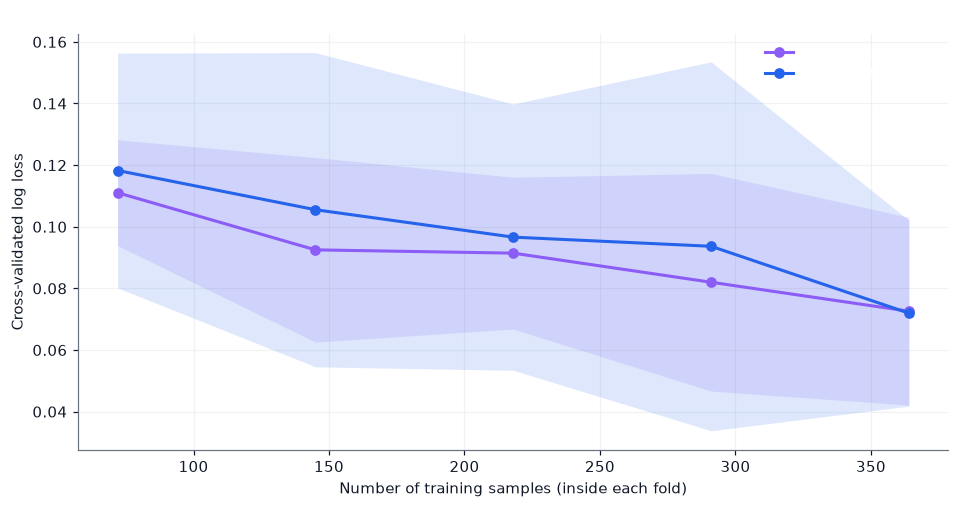

{'Logistic regression': [0.111, 0.093, 0.091, 0.082, 0.073], 'MLP (single)': [0.118, 0.106, 0.097, 0.094, 0.072]} (mean log loss for the training fractions [0.2, 0.4, 0.6, 0.8, 1.0] )


In [34]:
fractions = [0.3, 1.0] if QUICK_MODE else [0.2, 0.4, 0.6, 0.8, 1.0]
curves = {"Logistic regression": {f: [] for f in fractions}, "MLP (single)": {f: [] for f in fractions}}
t0 = time.time()
for fold, (tr_i, te_i) in enumerate(stratified_kfold(y_dev, 5, SEED)):
    for fr in fractions:
        sub = stratified_kfold  # placeholder to keep the namespace explicit
        r = np.random.default_rng(100 * fold + int(fr * 10)); chosen = []
        for c in (0, 1):
            idx = r.permutation(tr_i[y_dev[tr_i] == c]); chosen.append(idx[:max(3, int(round(fr * len(idx))))])
        chosen = np.concatenate(chosen)
        prep = Preprocessor(USE_LOG).fit(X_dev[chosen]); Xa, Xb = prep.transform(X_dev[chosen]), prep.transform(X_dev[te_i])
        curves["Logistic regression"][fr].append(log_loss(y_dev[te_i], logistic_proba(logistic_fit(Xa, y_dev[chosen], lam_dev), Xb)))
        curves["MLP (single)"][fr].append(log_loss(y_dev[te_i], mlp_proba(fit_mlp(Xa, y_dev[chosen], best_config, seed=SEED + fold), Xb)))
print(f"Done in {time.time() - t0:.0f} s")

fig, ax = plt.subplots(figsize=(8.8, 4.7))
n_train_sizes = [int(f * 0.8 * len(y_dev)) for f in fractions]
for m, data in curves.items():
    mean = np.array([np.mean(data[f]) for f in fractions]); sd = np.array([np.std(data[f]) for f in fractions])
    ax.plot(n_train_sizes, mean, marker="o", color=MODEL_COLORS[m], label=m); ax.fill_between(n_train_sizes, mean - sd, mean + sd, color=MODEL_COLORS[m], alpha=0.15, linewidth=0)
ax.set_xlabel("Number of training samples (inside each fold)"); ax.set_ylabel("Cross-validated log loss"); ax.set_title("Learning curves: more data helps, with diminishing returns")
ax.legend()
finish(fig, "14_learning_curves")
print({m: [round(float(np.mean(curves[m][f])), 3) for f in fractions] for m in curves}, "(mean log loss for the training fractions", fractions, ")")

Interpretation: when the curve is still decreasing at 100% of the training data, collecting more samples would still reduce the error, and the neural network (which has more parameters to estimate) tends to profit more from additional data than the logistic regression, whose curve flattens earlier. If the two curves converge, the extra flexibility brings nothing for this problem and sample size.

## 21. Limitations and scientific conclusion

### 21.1 Summary of the results (at a glance)

The figure below collects the main results of the final model on the test set.

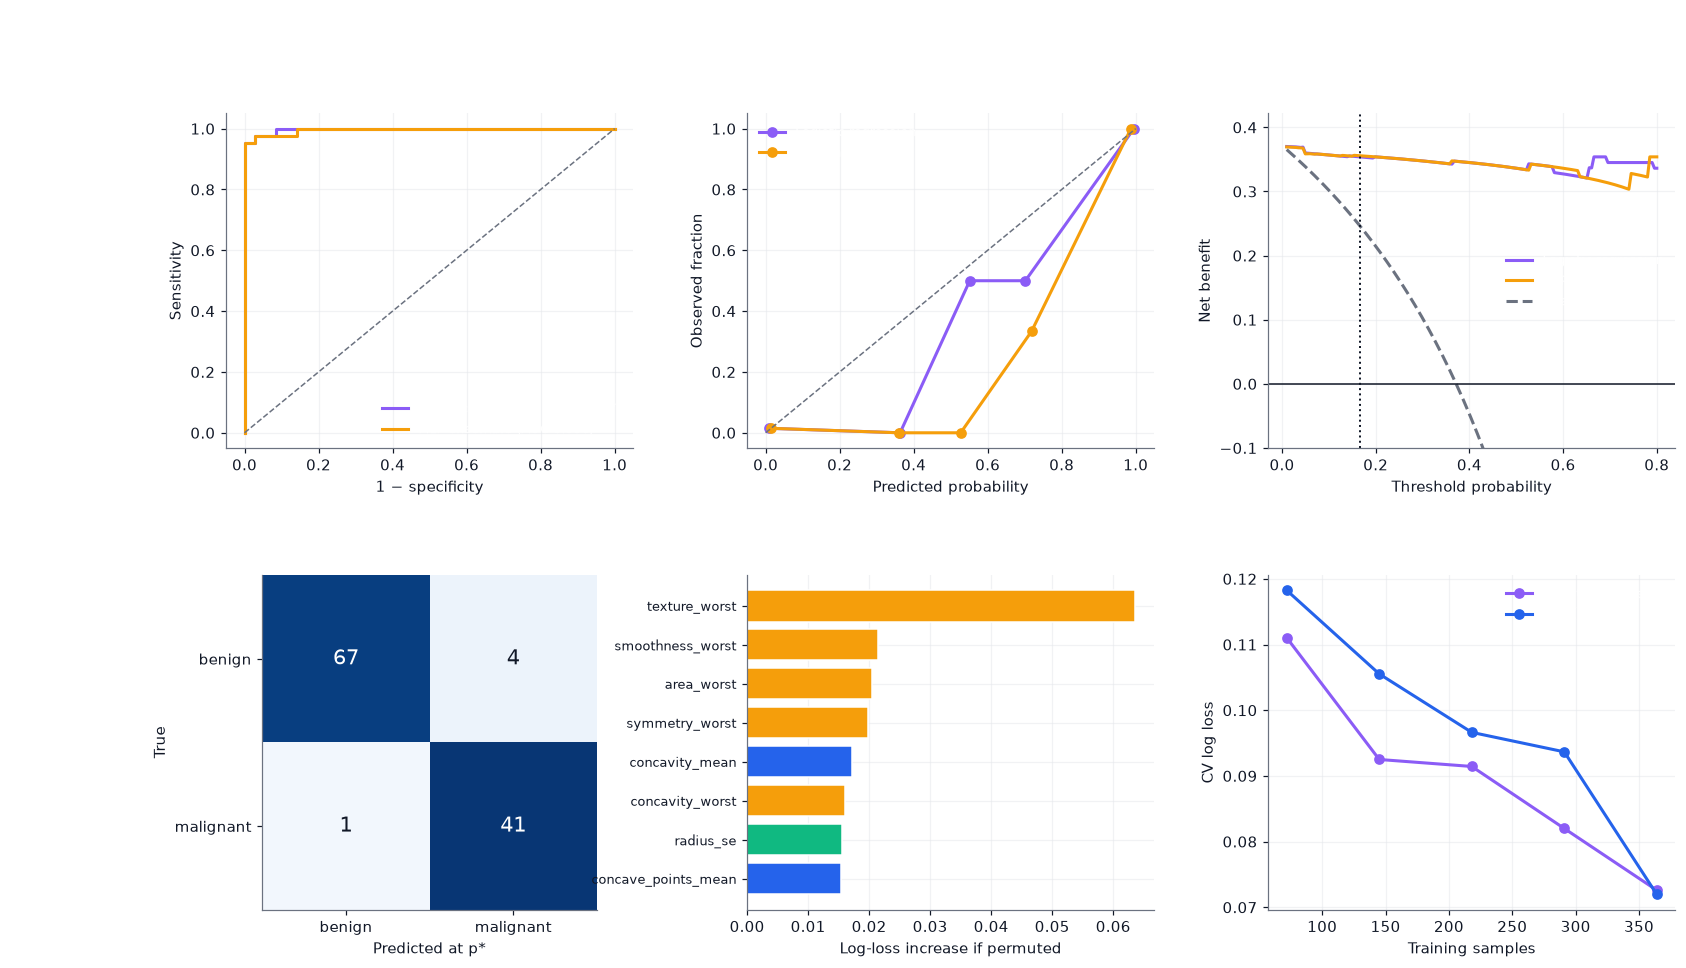

In [35]:
fig = plt.figure(figsize=(17, 9.4))
gs = fig.add_gridspec(2, 3, hspace=0.38, wspace=0.28)
ax = fig.add_subplot(gs[0, 0])
for m in ["Logistic regression", "MLP ensemble"]:
    fpr, tpr = roc_curve_np(y_test, test_prob[m]); ax.plot(fpr, tpr, color=MODEL_COLORS[m], label=f"{m} (AUC {auc_rank(y_test, test_prob[m]):.3f})")
ax.plot([0, 1], [0, 1], color=COLORS["gray"], linestyle="--", linewidth=1); ax.set_xlabel("1 \u2212 specificity"); ax.set_ylabel("Sensitivity"); ax.set_title("ROC"); ax.legend(loc="lower right", fontsize=8.5)
ax = fig.add_subplot(gs[0, 1])
for m in ["Logistic regression", "MLP ensemble"]:
    rel = reliability_bins(y_test, test_prob[m], 5); ax.plot(rel[:, 0], rel[:, 1], "o-", color=MODEL_COLORS[m], label=m)
ax.plot([0, 1], [0, 1], color=COLORS["gray"], linestyle="--", linewidth=1); ax.set_xlabel("Predicted probability"); ax.set_ylabel("Observed fraction"); ax.set_title("Calibration (test)"); ax.legend(fontsize=8.5)
ax = fig.add_subplot(gs[0, 2])
for m in ["Logistic regression", "MLP ensemble"]:
    ax.plot(ts, [net_benefit(y_test, test_prob[m], t) for t in ts], color=MODEL_COLORS[m], label=m)
ax.plot(ts, treat_all, color=COLORS["gray"], linestyle="--", label="treat all"); ax.axhline(0, color=COLORS["dark"], linewidth=1); ax.axvline(P_STAR, color=COLORS["dark"], linestyle=":", linewidth=1.3)
ax.set_ylim(-0.1, y_test.mean() + 0.05); ax.set_xlabel("Threshold probability"); ax.set_ylabel("Net benefit"); ax.set_title("Decision curve"); ax.legend(fontsize=8.5)
ax = fig.add_subplot(gs[1, 0])
im = ax.imshow(cm / cm.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=1); ax.grid(False)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]}", ha="center", va="center", fontsize=14, color="white" if cm[i, j] / cm[i].sum() > 0.55 else COLORS["dark"])
ax.set_xticks([0, 1]); ax.set_xticklabels(["benign", "malignant"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["benign", "malignant"]); ax.set_xlabel("Predicted at p*"); ax.set_ylabel("True"); ax.set_title("Confusion matrix (MLP ensemble)")
ax = fig.add_subplot(gs[1, 1])
y_ = np.arange(len(top))[::-1][:8]; ax.barh(y_, imp_single.loc[top[:8], "log-loss increase"], color=[GROUP_COLORS[n.split("_")[-1]] for n in top[:8]], edgecolor="white")
ax.set_yticks(y_); ax.set_yticklabels(top[:8], fontsize=8.5); ax.set_xlabel("Log-loss increase if permuted"); ax.set_title("Permutation importance (top 8)")
ax = fig.add_subplot(gs[1, 2])
for m, data in curves.items():
    mean = np.array([np.mean(data[f]) for f in fractions]); ax.plot(n_train_sizes, mean, marker="o", color=MODEL_COLORS[m], label=m)
ax.set_xlabel("Training samples"); ax.set_ylabel("CV log loss"); ax.set_title("Learning curves"); ax.legend(fontsize=8.5)
fig.suptitle("Breast-mass FNA classification: the final model at a glance (test set, n = %d, %d malignant)" % (len(y_test), int(y_test.sum())), fontsize=14, fontweight="bold", x=0.01, ha="left", y=0.98)
finish(fig, "15_results_dashboard", tight=False)

### 21.2 What the project supports

If your results resemble those typically obtained with this dataset: nuclear size and contour-irregularity features discriminate malignant from benign FNA samples **very well** (AUC close to 1); a regularized neural network and an ensemble achieve this with **well-behaved probabilities after calibration**; and a decision rule derived from explicit error costs trades a small number of false positives for very few missed malignancies. The decision curve shows whether basing decisions on the model is better than treating everyone or no one at the relevant thresholds.

### 21.3 What it does not support

1. **The neural network is not clearly better than logistic regression.** On this near-linearly-separable problem the paired comparisons (Sections 13 and 15) usually do not show a significant advantage; a neural network adds complexity, training randomness, and need for calibration. The honest conclusion may be *"matches the simpler baseline"*.
2. **Small, single-source data.** 569 samples from one institution and period (University of Wisconsin, 1990s), with features from a particular segmentation software and digitization. Performance on other hospitals, staining protocols, scanners, or modern digital pathology is **unknown**: there is no external validation. Distribution shift is the main threat to deployment.
3. **No patient-level information.** The file contains no patient identifiers beyond the sample ID, no repeated-measure information, and no demographics; independence of the samples and performance in subgroups (age, ethnicity, tumour size) **cannot be checked**.
4. **A narrow test set.** With 114 test samples and about 42 malignant ones, the intervals for sensitivity and specificity are wide (Section 15); a few errors can change the conclusion.
5. **Label and task definition.** The label is the diagnosis (benign or malignant) of a cytological sample; real decisions involve imaging, clinical findings, and histology, and the cost ratio 5 : 1 was an assumption.
6. **Feature importance is not causation** (Section 18).
7. **Tuning on a small dataset.** 12 random configurations and repeated cross-validation on 455 samples give a selected configuration whose cross-validation score is optimistic (Section 8.5); the untouched test set is the reference.

### 21.4 A checklist for reporting (inspired by TRIPOD and ML reporting guidelines)

| Item | Where in this notebook |
|---|---|
| Source, licence, inclusion criteria, size, class balance | Sections 2, 4 |
| Outcome definition and prediction horizon | Section 2 (benign vs malignant diagnosis; no time horizon) |
| Predictors and how they were measured | Sections 2.1, 4 |
| Missing data | Section 4 (none) |
| Split, leakage prevention, preprocessing inside folds | Sections 5, 7, 13 |
| Models, hyperparameters, how selected, number of configurations tried | Sections 10–12 |
| Performance measures with uncertainty | Sections 13, 15 |
| Calibration | Sections 14, 16 |
| Decision rule, costs, clinical usefulness | Sections 2.3, 14, 16 |
| Comparison with a simple baseline | Sections 10, 13, 15 |
| Interpretation and its caveats | Sections 18, 19 |
| Limitations | Section 21.3 |
| Code, seeds, versions, saved model | Section 22 |

## 22. Saving, documenting, and reusing the model

A model is only reusable if its **whole pipeline** is saved: the preprocessing (log transform flag, means, standard deviations), the networks, the calibration parameters, the decision threshold, and the metadata. We also write a short **model card** (intended use, data, performance, limitations).

The `predict_case` function validates the input (30 values, positive, not wildly outside the training range) and returns the calibrated probability, the decision, and the uncertainty. It is a **research demonstration, not a medical device**.

In [37]:

model_paths = []
for i, m in enumerate(final_models):
    path = os.path.join(ARTIFACT_DIR, f"mlp_member_{i + 1}.keras")
    m.save(path)
    model_paths.append(os.path.basename(path))

np.savez(
    os.path.join(ARTIFACT_DIR, "pipeline.npz"),
    mu=prep_final.mu,
    sd=prep_final.sd,
    log_transform=np.array(USE_LOG),
    lr_weights=w_lr,
    platt_mlp=np.array(platt_params["MLP ensemble"]),
    platt_lr=np.array(platt_params["Logistic regression"]),
    train_min=X_dev.min(axis=0),
    train_max=X_dev.max(axis=0)
)

bm_ens = binary_metrics(y_test, test_prob["MLP ensemble"] >= P_STAR)
lo_auc, hi_auc = bootstrap_ci(auc_rank, y_test, test_prob["MLP ensemble"])

metadata = {
    "project": "Breast-mass FNA classification (UCI Breast Cancer Wisconsin Diagnostic, DOI 10.24432/C5DW2B, CC BY 4.0)",
    "intended_use": "Teaching and research demonstration only. Not a medical device.",
    "features": FEATURE_NAMES,
    "preprocessing": f"log1p={USE_LOG}, then standardization with development-set means and standard deviations (pipeline.npz)",
    "split": {
        "development": int(len(y_dev)),
        "test": int(len(y_test)),
        "seed": SEED,
        "stratified": True
    },
    "model": {
        "type": "ensemble of MLPs",
        "members": ENSEMBLE_SIZE,
        "config": {
            k: (list(v) if isinstance(v, tuple) else v)
            for k, v in best_config.items()
        },
        "files": model_paths
    },
    "calibration": {
        "method": "Platt scaling fitted on out-of-fold development predictions",
        "a_b": [float(v) for v in platt_params["MLP ensemble"]]
    },
    "decision": {
        "cost_false_negative": COST_FN,
        "cost_false_positive": COST_FP,
        "threshold_p_star": P_STAR
    },
    "test_performance": {
        "AUC": float(auc_rank(y_test, test_prob["MLP ensemble"])),
        "AUC_95ci": [float(lo_auc), float(hi_auc)],
        "log_loss": float(log_loss(y_test, test_prob["MLP ensemble"])),
        "sensitivity_at_p_star": float(bm_ens["sensitivity"]),
        "specificity_at_p_star": float(bm_ens["specificity"]),
        "FN": bm_ens["FN"],
        "FP": bm_ens["FP"]
    },
    "cv_comparison_mean": {
        m: {
            k: float(v)
            for k, v in summary_cv.loc[
                m, ["log loss", "AUC", "cost at p*"]
            ].items()
        }
        for m in summary_cv.index
    },
    "versions": {
        "python": sys.version.split()[0],
        "keras": keras.__version__,
        "backend": keras.backend.backend(),
        "numpy": np.__version__
    },
}


# Convert NumPy data types to standard Python types for JSON serialization.
def json_safe(obj):
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, np.generic):
        return obj.item()
    raise TypeError(f"Object of type {type(obj).__name__} is not JSON serializable")


with open(os.path.join(ARTIFACT_DIR, "metadata.json"), "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False, default=json_safe)


model_card = f"""# Model card: breast-mass FNA classifier (teaching project)

**Intended use.** Educational demonstration of an end-to-end deep-learning project. NOT for clinical use.

**Data.** UCI Breast Cancer Wisconsin (Diagnostic), 569 samples, 30 nuclear features computed from digitized FNA images (212 malignant, 357 benign). Licence CC BY 4.0.

**Model.** Ensemble of {ENSEMBLE_SIZE} MLPs (config {metadata['model']['config']}), inputs preprocessed with log1p={USE_LOG} and standardization; probabilities calibrated by Platt scaling.

**Decision rule.** Malignant if calibrated p >= {P_STAR:.3f} (cost of a false negative = {COST_FN:g} x cost of a false positive; an assumption).

**Test performance (n = {len(y_test)}, {int(y_test.sum())} malignant).** AUC {metadata['test_performance']['AUC']:.3f} (95% CI {lo_auc:.3f}-{hi_auc:.3f}); sensitivity {bm_ens['sensitivity']:.3f}, specificity {bm_ens['specificity']:.3f} at the threshold; FN = {bm_ens['FN']}, FP = {bm_ens['FP']}.

**Limitations.** Single-source, 1990s data; no external validation; no patient-level or demographic information; wide intervals on a small test set; the neural network is not shown to be better than logistic regression; feature importance is not causal.
"""

with open(os.path.join(ARTIFACT_DIR, "MODEL_CARD.md"), "w", encoding="utf-8") as f:
    f.write(model_card)


def predict_case(features):
    """Calibrated malignancy probability, decision, and ensemble disagreement for ONE sample of 30 features (file order)."""

    x = np.asarray(features, dtype=np.float64)

    if x.shape != (30,) or not np.all(np.isfinite(x)) or np.any(x <= 0):
        raise ValueError(
            "Expected 30 finite, positive numbers in the order of FEATURE_NAMES."
        )

    outside = np.flatnonzero(
        (x < X_dev.min(axis=0)) | (x > X_dev.max(axis=0))
    )

    z = prep_final.transform(x[None, :])
    members = ensemble_members(final_models, z)[:, 0]

    p = float(
        platt_apply(
            np.array([members.mean()]),
            platt_params["MLP ensemble"]
        )[0]
    )

    return {
        "probability_malignant": round(p, 4),
        "decision": "malignant" if p >= P_STAR else "benign",
        "member_disagreement_sd": round(float(members.std()), 4),
        "features_outside_training_range": [
            FEATURE_NAMES[i] for i in outside
        ]
    }


print("Saved files:", sorted(os.listdir(ARTIFACT_DIR)))

print(
    "\nExample, test sample",
    int(ids_test[0]),
    "(true diagnosis:",
    "malignant" if y_test[0] else "benign",
    "):",
    predict_case(X_test[0])
)

reloaded = keras.models.load_model(
    os.path.join(ARTIFACT_DIR, model_paths[0])
)

print(
    "Reloaded member reproduces the predictions:",
    np.allclose(
        mlp_proba(reloaded, Xt_final[:10]),
        member_test[0][:10],
        atol=1e-5
    )
)


Saved files: ['MODEL_CARD.md', 'metadata.json', 'mlp_member_1.keras', 'mlp_member_10.keras', 'mlp_member_2.keras', 'mlp_member_3.keras', 'mlp_member_4.keras', 'mlp_member_5.keras', 'mlp_member_6.keras', 'mlp_member_7.keras', 'mlp_member_8.keras', 'mlp_member_9.keras', 'pipeline.npz']

Example, test sample 91813701 (true diagnosis: benign ): {'probability_malignant': 0.527, 'decision': 'malignant', 'member_disagreement_sd': 0.1528, 'features_outside_training_range': []}
Reloaded member reproduces the predictions: True


## 23. What did we learn? (the whole project in ten lines)

1. A project starts with a **question, a decision problem with costs, and a protocol** written before modelling ($p^{*} = c_{FP}/(c_{FP}+c_{FN})$).
2. **Validity checks, exploration, and the test split come first**; the test set stays locked until the end.
3. Preprocessing, inner tuning, and calibration are **fitted inside the training data** of each fold (no leakage).
4. **Logistic regression** (Newton's method, convex, verified gradient) is a strong baseline; a neural network must **beat it honestly**.
5. **Proper scoring rules** (log loss, Brier) reward honest probabilities; AUC alone does not.
6. **Random search** inside cross-validation finds a good region; the selected score is optimistic (winner's curse).
7. **Repeated CV and paired tests** compare models on identical folds; an ensemble reduces variance.
8. **Platt scaling** fixes monotone miscalibration without changing the AUC; the cost-based threshold needs calibrated probabilities.
9. **Net benefit** asks whether the model improves decisions; **uncertainty** (ensemble disagreement) supports referral to experts.
10. **Importance is a property of the model, not of the biology**; the report states the limitations, the data, and the code, and the model is saved with its whole pipeline.

### Key terms

| Term | Meaning |
|---|---|
| Positive class, prevalence | Malignant; the fraction of malignant samples |
| Cost-optimal threshold $p^{*}$ | $c_{FP}/(c_{FP}+c_{FN})$ for calibrated probabilities |
| Newton's method / IRLS | Second-order optimization of logistic regression |
| Proper scoring rule | A loss minimized in expectation by the true probability (log loss, Brier) |
| Platt scaling | $\sigma(a\,\text{logit}(p) + b)$ fitted on held-out predictions |
| Out-of-fold prediction | A prediction for a sample by a model that did not train on it |
| Cross-fitting | Fitting a correction on some folds and applying it to others |
| Net benefit | $TP/n - (FP/n)\,t/(1-t)$; decision-curve analysis |
| Ensemble disagreement | SD of the member probabilities (epistemic uncertainty) |
| Permutation importance | Performance drop when a feature (or group) is shuffled |
| Winner's curse | Optimism of the best of many tried configurations |
| Model card | A short document describing a model's use, data, performance, and limits |

## 24. Exercises: extending the project

### A. Mathematics

1. Show that for logistic regression the Hessian $X^{\top}WX + R$ is positive definite when $\lambda > 0$, and explain why this implies a unique minimum. What happens to Newton's method if the classes are perfectly separable and $\lambda = 0$?
2. Starting from $\mathbb{E}[\text{Brier}] = p(1-q)^2 + (1-p)q^2$, prove that it is minimized at $q = p$, and show that the *minimum value* equals $p(1-p)$ (the irreducible uncertainty).
3. Derive the cost-optimal threshold when the cost of a **correct** malignant decision is $c_{TP}$ and of a correct benign decision is $c_{TN}$ (only the differences $c_{FP}-c_{TN}$ and $c_{FN}-c_{TP}$ matter).
4. Verify algebraically that $\text{NB}(t) = \pi - \text{cost}/c_{FN}$ when $c_{FP}/c_{FN} = t/(1-t)$, and show that the net benefit of "treat all" crosses zero at $t = \pi$.
5. For $S$ ensemble members with pairwise correlation $\rho$ and individual variance $\sigma^2$, derive $\operatorname{Var}(\bar{p}) = \frac{\sigma^2}{S}(1 + (S-1)\rho)$. What is the limit when $S \to \infty$ and what does it mean for the value of a very large ensemble?
6. Show that Platt scaling with $a > 0$ preserves the ranking of the predictions, hence the AUC, but changes the log loss.
7. Explain why the corrected resampled $t$-test needs the factor $n_{\text{test}}/n_{\text{train}}$ and compute it for 5-fold CV with 455 samples.

### B. Programming

1. Add a **tree-based** baseline (for example, a depth-limited decision tree or a small random forest written in NumPy) and compare it with logistic regression and the MLP: on tabular data trees are often strong competitors (Grinsztajn *et al.*, 2022).
2. Replace the 5 : 1 cost ratio by 10 : 1 and 2 : 1. How do the threshold, sensitivity, specificity, and the decision curve change? Which ratio makes the neural network useful relative to logistic regression?
3. Use **only the 10 'worst' features** (or only the 'mean' features) and repeat the comparison: how much performance is lost? Is the model more or less stable?
4. Implement **nested cross-validation** for the whole MLP search (outer 5 folds, inner random search of 6 configurations) to estimate the performance of the *procedure* and compare it with the cross-validated score of the selected configuration (the winner's curse).
5. Replace Platt scaling by **isotonic regression** (a monotone, piecewise-constant fit; pool-adjacent-violators algorithm) and compare the cross-fitted Brier score and ECE.
6. Train the MLP with **class weights** (Notebook 06) and show their effect on calibration before and after Platt scaling.
7. Add **SHAP-like** local explanations by computing, for one test sample, the change in the predicted probability when each feature group is replaced by its training mean.
8. Evaluate **robustness to measurement noise**: add Gaussian noise of increasing size to the test features and plot the AUC, the calibration, and the cost.
9. Train a **denoising autoencoder** (Notebook 11) on the 30 features and use its reconstruction error as an out-of-distribution score: does it flag test samples with unusual measurements?

### C. Research thinking

1. Which additional data would you need to claim that the model is ready for use in a clinic? (Think: external cohorts, prospective validation, subgroups, workflow integration, regulation.)
2. The test set has about 42 malignant samples. How many malignant samples would you need to estimate a sensitivity of about 0.97 with a 95% interval of width 0.05? (Use the Wilson formula or the normal approximation $n \approx 4\cdot 1.96^2\,p(1-p)/w^2$.)
3. A reviewer asks: *"How do you know that the model does not use an artefact of the imaging process instead of the biology?"* Propose two experiments.
4. The cost ratio 5 : 1 was an assumption. How would you elicit it from clinicians and patients, and how would you present the sensitivity of the conclusions to it?

## 25. Further exploration and references

### Dataset

- Wolberg, W., Mangasarian, O., Street, N., and Street, W. (1995). *Breast Cancer Wisconsin (Diagnostic)* [Dataset]. UCI Machine Learning Repository. <https://doi.org/10.24432/C5DW2B> (CC BY 4.0).
- Street, W. N., Wolberg, W. H., and Mangasarian, O. L. (1993). Nuclear feature extraction for breast tumor diagnosis. *IS&T/SPIE International Symposium on Electronic Imaging: Science and Technology*, 1905, 861–870.
- Wolberg, W. H. and Mangasarian, O. L. (1990). Multisurface method of pattern separation for medical diagnosis applied to breast cytology. *Proceedings of the National Academy of Sciences*, 87, 9193–9196.

### Evaluation, calibration, and clinical usefulness

- Collins, G. S., Reitsma, J. B., Altman, D. G., and Moons, K. G. M. (2015). Transparent reporting of a multivariable prediction model for individual prognosis or diagnosis (TRIPOD). *Annals of Internal Medicine*, 162, 55–63.
- Vickers, A. J. and Elkin, E. B. (2006). Decision curve analysis: a novel method for evaluating prediction models. *Medical Decision Making*, 26, 565–574.
- Platt, J. (1999). Probabilistic outputs for support vector machines and comparisons to regularized likelihood methods. *Advances in Large Margin Classifiers*.
- Guo, C., Pleiss, G., Sun, Y., and Weinberger, K. Q. (2017). On calibration of modern neural networks. *ICML*.
- Steyerberg, E. W. (2019). *Clinical Prediction Models* (2nd ed.). Springer.
- Varma, S. and Simon, R. (2006). Bias in error estimation when using cross-validation for model selection. *BMC Bioinformatics*, 7, 91.
- Nadeau, C. and Bengio, Y. (2003). Inference for the generalization error. *Machine Learning*, 52, 239–281.

### Methods

- Bergstra, J. and Bengio, Y. (2012). Random search for hyper-parameter optimization. *Journal of Machine Learning Research*, 13, 281–305.
- Breiman, L. (2001). Random forests (permutation importance). *Machine Learning*, 45, 5–32.
- Lakshminarayanan, B., Pritzel, A., and Blundell, C. (2017). Simple and scalable predictive uncertainty estimation using deep ensembles. *NeurIPS*.
- Grinsztajn, L., Oyallon, E., and Varoquaux, G. (2022). Why do tree-based models still outperform deep learning on typical tabular data? *NeurIPS Datasets and Benchmarks*.

### Suggested reading

- Goodfellow, Bengio, and Courville — *Deep Learning*: chapter 11 (practical methodology).
- Chollet — *Deep Learning with Python*: the chapters on the universal workflow of machine learning and on best practices.
- Géron — *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow*: the end-to-end machine-learning project chapter.

---

## The end of the Keras learning path — and what comes next

You have now seen the whole workflow: from the neuron and the gradient (Notebooks 01–02), through the Keras API (03), classification and regression on biological data (04–05), optimization and regularization (06), honest evaluation (07), convolutional networks, transfer learning, and sequence models (08–10), representation learning (11), to a complete project (12).

The **next learning path** goes below the Keras API into the **TensorFlow ecosystem**: tensor operations, automatic differentiation with `GradientTape`, input pipelines with `tf.data`, custom layers and training loops, and building models at a lower level. Everything you verified by hand in NumPy in these notebooks — gradients, losses, optimizers — is exactly what those tools automate, so you will be able to read and write such code with confidence.